# Presentation 4: Where Should a UK Graduate Start a U.S. Analytics Career?

**Business question:** *Which U.S. metro areas offer the best combination of posting volume, salary, and entry-level accessibility for data and analytics roles, what skills do employers in those metros ask for, and where should a UK graduate apply first?*

**Dataset:** `US_Data_AI_Jobs_2026.csv` (NextGig Multi-ATS Job Postings Snapshot, Summer 2026)

**Persona:** a UK graduate who is new to the U.S. market and sensitive to cost of living. Visa sponsorship is *not* analysed because almost no postings mention it (see Limitations). We **do** flag postings that explicitly require **U.S. citizenship or a security clearance**, because a UK graduate cannot meet those requirements whatever their visa status.

| # | Required evidence | Where it is |
|---|---|---|
| 1 | Preprocessing and stopword rationale | Section 3 |
| 2 | N-gram visual | Section 5 |
| 3 | TF-IDF / similarity analysis | Sections 6-7 |
| 4 | K-means with interpretation | Section 8 |
| 5 | LDA and pyLDAvis interpretation | Section 9 |
| 6 | State choropleths | Section 11 |
| 7 | City bubble map | Section 11 |
| 8 | Salary / disclosure geography | Section 11 |
| 9 | Geographic skill concentration | Section 11 |
| 10 | Normalized measure across states | Section 12 |
| 11 | Three recommended locations | Section 13 |
| 12 | Limitations and sampling bias | Section 14 |
| + | Industry question | Section 15 |

## 1. Setup and Load
Mount Drive (in Colab), import libraries, load the file, confirm the required columns exist, and audit missing data.

In [1]:
import sys, os, re, importlib, subprocess, warnings
warnings.filterwarnings('ignore')
IN_COLAB = 'google.colab' in sys.modules

for pkg in ['wordcloud', 'pyLDAvis', 'reverse_geocoder']:
    try:
        importlib.import_module(pkg)
    except ImportError:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', pkg], check=False)

import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio
from plotly.subplots import make_subplots
import matplotlib.pyplot as plt
from wordcloud import WordCloud
from collections import Counter
from itertools import combinations
from IPython.display import display

pio.renderers.default = 'colab' if IN_COLAB else 'notebook_connected'
pd.set_option('display.max_colwidth', 100)
RANDOM_STATE = 42

if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')

candidates = [
    '/content/drive/MyDrive/Colab Notebooks/US_Data_AI_Jobs_2026.csv',
    'US_Data_AI_Jobs_2026.csv',
    'Presentation 4 Jobs data.csv',
]
DATA_PATH = next(p for p in candidates if os.path.exists(p))
raw = pd.read_csv(DATA_PATH)
print(f'Loaded {DATA_PATH}: {raw.shape[0]:,} rows x {raw.shape[1]} columns')

# Shared presentation styling (same look as our earlier notebook)
presentation_layout = dict(
    font=dict(family='Arial, sans-serif', size=12, color='#2c3e50'),
    title=dict(font=dict(size=18, family='Arial Black', color='#1a252f'), x=0.05, y=0.95),
    paper_bgcolor='#f8f9fa',
    plot_bgcolor='#ffffff',
    margin=dict(l=60, r=40, t=80, b=60),
    legend=dict(bgcolor='rgba(255,255,255,0.8)', bordercolor='#e2e8f0', borderwidth=1),
)

def style(fig, height=None, **kwargs):
    fig.update_layout(presentation_layout)
    if height:
        fig.update_layout(height=height)
    if kwargs:
        fig.update_layout(**kwargs)
    return fig

Loaded Presentation 4 Jobs data.csv: 2,905 rows x 23 columns


In [2]:
required_cols = ['title', 'company_name', 'company_industry', 'city', 'state', 'location_raw',
                 'latitude', 'longitude', 'is_remote', 'salary_min', 'salary_max', 'salary_period',
                 'salary_currency', 'skills', 'posted_at', 'description_text']
missing_cols = [c for c in required_cols if c not in raw.columns]
print('Required columns missing:', missing_cols or 'none - all present')

missing = (raw.isna().mean() * 100).sort_values(ascending=False).round(1).reset_index()
missing.columns = ['Column', '% Missing']
display(missing)

fig = px.bar(missing[missing['% Missing'] > 0], x='% Missing', y='Column', orientation='h',
             title='Missing-Data Audit: Share of Postings Missing Each Field',
             color='% Missing', color_continuous_scale='Tealgrn')
style(fig, height=450, yaxis={'categoryorder': 'total ascending'}, coloraxis_showscale=False).show()

Required columns missing: none - all present


,Column,% Missing
0,url,100.0
1,company_industry,90.4
2,department,90.0
3,posted_at,72.4
4,salary_max,36.0
5,salary_min,35.1
6,salary_period,34.4
7,salary_currency,32.5
8,state,16.6
9,skills,11.0


**Missing-data takeaways:** `url` is completely empty and `company_industry` and `department` are mostly empty, so industry has to be inferred (Section 15). About a third of postings have no salary, so every salary figure in this notebook is based on *disclosed* salaries only. `posted_at` is sparse, so we do not analyse posting dates.

## 2. Subset to Our Research Focus
This is the most important data-prep step.

**Structured filter: U.S. only.** Every row says `country = United States`, but `location_raw` shows postings from Toronto, Montréal, Mexico, Poland, Peru and the UK. We drop those, plus Puerto Rico (a U.S. territory with no state-level population or price-parity data). Short codes like `CAN`, `MX` and `PR` are matched case-sensitively and with word boundaries, so that `India` does not match **India**napolis.

**Keyword filter on `title`** (regex, case-insensitive):
`analyst | analytics | business intelligence | data scientist | data engineer | insights | reporting`

This keeps classic data and business analysts and adds adjacent data-and-analytics titles, which brings the subset into the professor's 300-1,500 range.

In [3]:
NON_US_PATTERN = (r'Canada|\bCAN\b|Toronto|Ontario|Quebec|Montr|Mississauga|Markham|Brampton|'
                  r'Vancouver|British Columbia|New Brunswick|Alberta|Poland|Peru|Mexico|\bMX\b|'
                  r'\bIndia\b|United Kingdom|England|Remote-UK|Puerto Rico|,\s*PR\s*,')
TITLE_KEYWORDS = r'analyst|analytics|business intelligence|data scientist|data engineer|insights|reporting'

location_text = raw['location_raw'].fillna('') + ' ' + raw['city'].fillna('')
non_us_mask = location_text.str.contains(NON_US_PATTERN, regex=True)
us = raw[~non_us_mask].copy()

title_mask = us['title'].fillna('').str.contains(TITLE_KEYWORDS, case=False, regex=True)
df = us[title_mask].copy().reset_index(drop=True)

# For transparency: what would we pull in if we also searched skills/description?
text_only_hits = (~title_mask) & (
    us['skills'].fillna('').str.contains(TITLE_KEYWORDS, case=False, regex=True) |
    us['description_text'].fillna('').str.contains(TITLE_KEYWORDS, case=False, regex=True))

funnel = pd.DataFrame({
    'Step': ['All postings in file', 'Removed: non-U.S. / territory locations', 'U.S. postings',
             'Kept: title matches data & analytics keywords (FINAL SUBSET)'],
    'Postings': [len(raw), int(non_us_mask.sum()), len(us), len(df)],
})
display(funnel)
print(f'Not used: {int(text_only_hits.sum())} more postings mention a keyword only in skills/description '
      '(e.g. an HR manager who "owns reporting"). We judged those off-target for an analytics job hunt.')
print('Sample of removed non-U.S. locations:', raw.loc[non_us_mask, 'location_raw'].value_counts().head(8).index.tolist())

,Step,Postings
0,All postings in file,2905
1,Removed: non-U.S. / territory locations,216
2,U.S. postings,2689
3,Kept: title matches data & analytics keywords (FINAL SUBSET),753


Not used: 1554 more postings mention a keyword only in skills/description (e.g. an HR manager who "owns reporting"). We judged those off-target for an analytics job hunt.
Sample of removed non-U.S. locations: ['Toronto,ON,Canada', 'Toronto,Ontario,Canada', 'Montreal,QC,Canada', 'Mississauga,ON,Canada', 'Toronto,Canada', 'Poland', 'Vancouver,BC,Canada', 'Peru']


In [4]:
title_counts = df['title'].value_counts().reset_index()
title_counts.columns = ['Job Title', 'Count']
fig = px.bar(title_counts.head(15), x='Count', y='Job Title', orientation='h',
             title='Demand Volume: Top 15 Titles in Our Data & Analytics Subset',
             color='Count', color_continuous_scale=px.colors.sequential.Tealgrn)
fig.update_traces(marker_line_color='#2c3e50', marker_line_width=1)
style(fig, height=550, yaxis={'categoryorder': 'total ascending'}, coloraxis_showscale=False).show()

## 3. Text Cleaning and Stopword Rationale
Pipeline: strip HTML tags and entities -> remove URLs -> remove emails -> lowercase -> keep letters only -> drop stopwords and words of 2 or fewer letters.

**Custom stopwords and why we added them.** These are job-ad boilerplate words that appear in nearly every posting, so they say nothing about the *kind* of job:

| Group | Words | Why remove |
|---|---|---|
| Hiring boilerplate | role, position, opportunity, candidate, join, company, team, teams | Appears in every ad regardless of job type |
| Duty verbs | responsible, responsibilities, ensure, support, help, provide, work, working, including, within, across, using | Generic duty language with no job-type signal |
| Requirement fillers | ability, strong, preferred, required, requirements, plus, looking, new, will | Describe *how much*, not *what* |

**Words we deliberately keep:** `remote`, `hybrid`, `years`, `experience`, `entry`, `junior`, `senior`, `sql`, `excel`, `python`, `system`. Our question depends on work setting, experience level and tools, so removing these would destroy meaning we need.

In [5]:
import nltk
nltk.download('stopwords', quiet=True)
from nltk.corpus import stopwords

CUSTOM_STOPWORDS = {
    'role', 'position', 'opportunity', 'candidate', 'join', 'company', 'team', 'teams',
    'responsible', 'responsibilities', 'ensure', 'support', 'help', 'provide', 'work', 'working',
    'including', 'within', 'across', 'using', 'ability', 'strong', 'preferred', 'required',
    'requirements', 'plus', 'looking', 'new', 'will',
}
PROTECTED_WORDS = {'remote', 'hybrid', 'years', 'experience', 'entry', 'junior', 'senior',
                   'sql', 'excel', 'python', 'system'}
STOPWORDS = (set(stopwords.words('english')) | CUSTOM_STOPWORDS) - PROTECTED_WORDS

desc = df['description_text'].fillna('')
noise_audit = pd.DataFrame({
    'Noise type': ['HTML tags', 'HTML entities', 'URLs', 'Emails'],
    'Postings affected': [int(desc.str.contains(r'<[^>]+>').sum()), int(desc.str.contains(r'&\w+;').sum()),
                          int(desc.str.contains(r'http\S+|www\.\S+').sum()),
                          int(desc.str.contains(r'\S+@\S+\.\w+').sum())],
})
display(noise_audit)

def clean_text(text):
    text = str(text)
    text = re.sub(r'<[^>]+>', ' ', text)
    text = re.sub(r'&\w+;', ' ', text)
    text = re.sub(r'http\S+|www\.\S+', ' ', text)
    text = re.sub(r'\S+@\S+\.\w+', ' ', text)
    text = text.replace('‑', '-').lower()
    text = re.sub(r'[^a-z\s]', ' ', text)
    return ' '.join(w for w in text.split() if w not in STOPWORDS and len(w) > 2)

df['raw_text'] = (df['title'].fillna('') + '. ' + desc).str.lower()
df['clean_text'] = (df['title'].fillna('') + ' ' + desc).apply(clean_text)

example = df.iloc[0]
print('BEFORE:', example['raw_text'][:300], '\n')
print('AFTER: ', example['clean_text'][:300])

,Noise type,Postings affected
0,HTML tags,0
1,HTML entities,0
2,URLs,0
3,Emails,0


BEFORE: associate director, us oncology insights. identify business needs and build research plans lead external agency market research projects and manage budgets translate insights into forecasting assumptions and strategic actions apply ai tools to research execution and analysis create presentations hig 

AFTER:  associate director oncology insights identify business needs build research plans lead external agency market research projects manage budgets translate insights forecasting assumptions strategic actions apply tools research execution analysis create presentations highlighting actionable insights co


**Note:** the NextGig `description_text` is already a derived, plain-text summary, so the HTML/URL/email steps remove little or nothing (see the audit table). We keep them so the pipeline is safe to reuse on raw scraped text. The title is added to the description because titles carry the strongest job-type signal.

## 4. Feature Engineering from Text
* **Length:** character and word counts.
* **Remote flag:** `is_remote` OR "remote" in the location or title.
* **Tech-skill flags:** regex word-boundary matches in skills + description.
* **Urgency flag:** "urgent", "immediate", "asap", "start immediately".
* **Years of experience (regex):** the smallest number before "years" when "experience" appears within the next 40 characters (catches "3+ years of experience", "2-4 years relevant experience", "at least 1 year of experience").
* **Seniority:** title contains senior / sr / lead / principal / staff / manager / director / head / vp / chief / architect.
* **Entry-level accessible (combined rule):** *not* a senior title **AND** (regex finds 2 or fewer years **OR** no years stated). Following the professor's advice, we never search for the phrase "entry-level".
* **Clearance / citizenship flag:** "security clearance", "TS/SCI", "top secret", "U.S. citizen(ship)". **UK-accessible** = entry-accessible **and** no clearance or citizenship requirement.
* **Salary:** from `salary_min` / `salary_max` only, annualized (hourly x 2,080, weekly x 52, monthly x 12). Junk `salary_period` values are kept only if the amount is clearly annual (at least $20k). Values outside $20k-$500k are treated as errors. We also flag postings that mention a salary inside the text, which is rare (the professor estimated about 3%).

In [6]:
df['char_count'] = df['description_text'].fillna('').str.len()
df['word_count'] = df['description_text'].fillna('').str.split().str.len()

df['remote_flag'] = df['is_remote'].fillna(False).astype(bool) | \
    (df['location_raw'].fillna('') + ' ' + df['city'].fillna('') + ' ' + df['title'].fillna('')).str.contains('remote', case=False)
df['work_setting'] = np.where(df['remote_flag'], 'Remote', 'On-site / Hybrid')

skill_text = (df['skills'].fillna('') + ' ' + df['description_text'].fillna('')).str.lower()
TECH_SKILLS = {
    'SQL': r'\bsql\b', 'Python': r'\bpython\b', 'Excel': r'\bexcel\b', 'Tableau': r'\btableau\b',
    'Power BI': r'\bpower\s?bi\b', 'R': r'\br\b(?!&)', 'Snowflake': r'\bsnowflake\b', 'AWS': r'\baws\b',
    'Azure': r'\bazure\b', 'Looker': r'\blooker\b', 'dbt': r'\bdbt\b', 'Spark': r'\bspark\b',
    'Machine Learning': r'machine learning|\bml\b', 'GenAI / LLM': r'genai|generative ai|\bllms?\b',
}
for name, pattern in TECH_SKILLS.items():
    df[f'skill_{name}'] = skill_text.str.contains(pattern, regex=True)

df['urgent_flag'] = df['description_text'].fillna('').str.contains(
    r'\burgent|\bimmediate(ly)?\b|\basap\b|start immediately', case=False, regex=True)

YEARS_PATTERN = r'(?:at least|minimum of|min\.?)?\s*(\d{1,2})\s*\+?\s*(?:-|–|to)?\s*(?:\d{1,2})?\s*\+?\s*(?:years?|yrs?)\b(?=[^.]{0,40}experience)'

def min_years(text):
    hits = [int(h) for h in re.findall(YEARS_PATTERN, str(text).lower()) if int(h) <= 20]
    return min(hits) if hits else np.nan

df['years_required'] = df['description_text'].apply(min_years)

SENIOR_PATTERN = r'\bsenior\b|\bsr\.?\b|\blead\b|\bprincipal\b|\bstaff\b|\bmanager\b|\bdirector\b|\bhead\b|\bvp\b|vice president|\bchief\b|\barchitect\b'
df['senior_title'] = df['title'].fillna('').str.contains(SENIOR_PATTERN, case=False, regex=True)
df['entry_accessible'] = (~df['senior_title']) & (df['years_required'].isna() | (df['years_required'] <= 2))

CLEARANCE_PATTERN = r'security clearance|\bclearance\b|ts/sci|top secret|u\.?s\.? citizen|citizenship required|must be a u\.?s\.?'
full_text = (df['title'].fillna('') + ' ' + df['description_text'].fillna('') + ' ' + df['skills'].fillna('')).str.lower()
df['clearance_or_citizenship'] = full_text.str.contains(CLEARANCE_PATTERN, regex=True)
df['uk_accessible'] = df['entry_accessible'] & ~df['clearance_or_citizenship']
df['experience_level'] = np.select(
    [df['senior_title'], df['years_required'] > 2, df['entry_accessible']],
    ['Senior title', 'Mid (3+ yrs, non-senior title)', 'Entry-accessible'], default='Other')

period = df['salary_period'].fillna('').str.lower().str.strip()
mult = np.select([period.str.contains('hour'), period.str.contains('week'), period.str.contains('month'),
                  period.str.contains(r'year|annu|yr')], [2080, 52, 12, 1], default=np.nan)
smin = df['salary_min'].where(df['salary_min'] > 0)
smax = df['salary_max'].where(df['salary_max'] > 0)
mult = np.where(np.isnan(mult) & (smin >= 20000), 1, mult)
usd = df['salary_currency'].fillna('USD').str.upper().str.contains('USD|\\$')
df['salary_annual_min'] = (smin * mult).where(usd)
df['salary_annual_max'] = (smax * mult).where(usd)
df['salary_mid'] = df[['salary_annual_min', 'salary_annual_max']].mean(axis=1)
df['salary_mid'] = df['salary_mid'].where(df['salary_mid'].between(20000, 500000))
df['salary_disclosed'] = df['salary_mid'].notna()
df['salary_band'] = pd.cut(df['salary_mid'], [0, 100000, 200000, np.inf],
                           labels=['Under $100K', '$100K-$200K', '$200K+'])
df['salary_in_text'] = df['description_text'].fillna('').str.contains(r'\$\s?\d{2,3}(?:,\d{3}|k)', case=False)

feature_summary = pd.DataFrame({
    'Feature': ['Median word count', 'Remote postings', 'Urgency language', 'Years-of-experience found by regex',
                'Senior titles', 'Entry-accessible (combined rule)', 'Requires clearance / U.S. citizenship',
                'UK-accessible (entry-accessible, no clearance)', 'Salary disclosed (usable)',
                'Salary mentioned inside text'],
    'Value': [f"{df['word_count'].median():.0f} words", f"{df['remote_flag'].mean():.1%}", f"{df['urgent_flag'].mean():.1%}",
              f"{df['years_required'].notna().mean():.1%}", f"{df['senior_title'].mean():.1%}",
              f"{df['entry_accessible'].mean():.1%}", f"{df['clearance_or_citizenship'].mean():.1%}",
              f"{df['uk_accessible'].mean():.1%}", f"{df['salary_disclosed'].mean():.1%}",
              f"{df['salary_in_text'].mean():.1%}"],
})
display(feature_summary)

,Feature,Value
0,Median word count,150 words
1,Remote postings,13.9%
2,Urgency language,0.4%
3,Years-of-experience found by regex,59.8%
4,Senior titles,44.6%
5,Entry-accessible (combined rule),37.5%
6,Requires clearance / U.S. citizenship,8.1%
7,"UK-accessible (entry-accessible, no clearance)",33.6%
8,Salary disclosed (usable),63.9%
9,Salary mentioned inside text,0.0%


In [7]:
skill_share = pd.DataFrame({'Skill': list(TECH_SKILLS),
                            'Share (%)': [df[f'skill_{s}'].mean() * 100 for s in TECH_SKILLS]})
fig = px.bar(skill_share.sort_values('Share (%)'), x='Share (%)', y='Skill', orientation='h',
             title='Tech-Skill Flags: Share of Postings Mentioning Each Tool',
             color='Share (%)', color_continuous_scale='Mint',
             text=skill_share.sort_values('Share (%)')['Share (%)'].round(1).astype(str) + '%')
style(fig, height=520, coloraxis_showscale=False).show()

fig = px.histogram(df.dropna(subset=['years_required']), x='years_required', nbins=15,
                   title='Years of Experience Required (Regex-Extracted)',
                   labels={'years_required': 'Minimum years required'}, color_discrete_sequence=['#16a085'])
style(fig, bargap=0.08).show()

level_counts = df['experience_level'].value_counts().reset_index()
level_counts.columns = ['Level', 'Count']
fig = px.pie(level_counts, values='Count', names='Level', hole=0.4,
             title='Entry-Level Accessibility (Combined Rule)',
             color_discrete_sequence=['#16a085', '#2c3e50', '#2980b9', '#95a5a6'])
fig.update_traces(textposition='inside', textinfo='percent+label', marker=dict(line=dict(color='#ffffff', width=2)))
style(fig).show()

fig = px.histogram(df.dropna(subset=['salary_mid']), x='salary_mid', nbins=35, marginal='box',
                   title='Compensation Benchmarks: Annualized Salary Midpoint (Disclosed Only)',
                   labels={'salary_mid': 'Annual salary midpoint ($)'}, color_discrete_sequence=['#2980b9'])
style(fig, bargap=0.08, xaxis_tickformat='$,.0f').show()

fig = px.box(df.dropna(subset=['salary_mid']), x='experience_level', y='salary_mid', color='work_setting',
             title='Salary Spread by Experience Level and Work Setting',
             labels={'experience_level': '', 'salary_mid': 'Annual salary ($)', 'work_setting': 'Setting'},
             color_discrete_sequence=['#1abc9c', '#34495e'])
style(fig, height=550, yaxis_tickformat='$,.0f', boxmode='group').show()

## 5. Text Visualization
N-grams after cleaning, word clouds before vs after cleaning, then the slice we care about: **entry-accessible postings**.

In [8]:
def get_ngrams(series, n):
    out = []
    for text in series:
        words = text.split()
        out.extend(' '.join(words[i:i + n]) for i in range(len(words) - n + 1))
    return out

def ngram_chart(series, n, label, scale, subset_label):
    counts = Counter(get_ngrams(series, n)).most_common(15)
    ngram_df = pd.DataFrame(counts, columns=['Term', 'Frequency'])
    fig = px.bar(ngram_df, x='Frequency', y='Term', orientation='h',
                 title=f'Contextual Vocabulary: Top 15 {label}s ({subset_label})',
                 color='Frequency', color_continuous_scale=scale)
    fig.update_traces(marker_line_color='#2c3e50', marker_line_width=1)
    style(fig, height=450, yaxis={'categoryorder': 'total ascending'}, coloraxis_showscale=False,
          margin=dict(l=180, r=40, t=80, b=60)).show()

raw_tokens = df['raw_text'].str.replace(r'[^a-z\s]', ' ', regex=True)
ngram_chart(raw_tokens, 1, 'Unigram', 'Greys', 'BEFORE cleaning')
for n, label, scale in [(1, 'Unigram', 'Tealgrn'), (2, 'Bigram', 'Mint'), (3, 'Trigram', 'Ice')]:
    ngram_chart(df['clean_text'], n, label, scale, 'after cleaning')

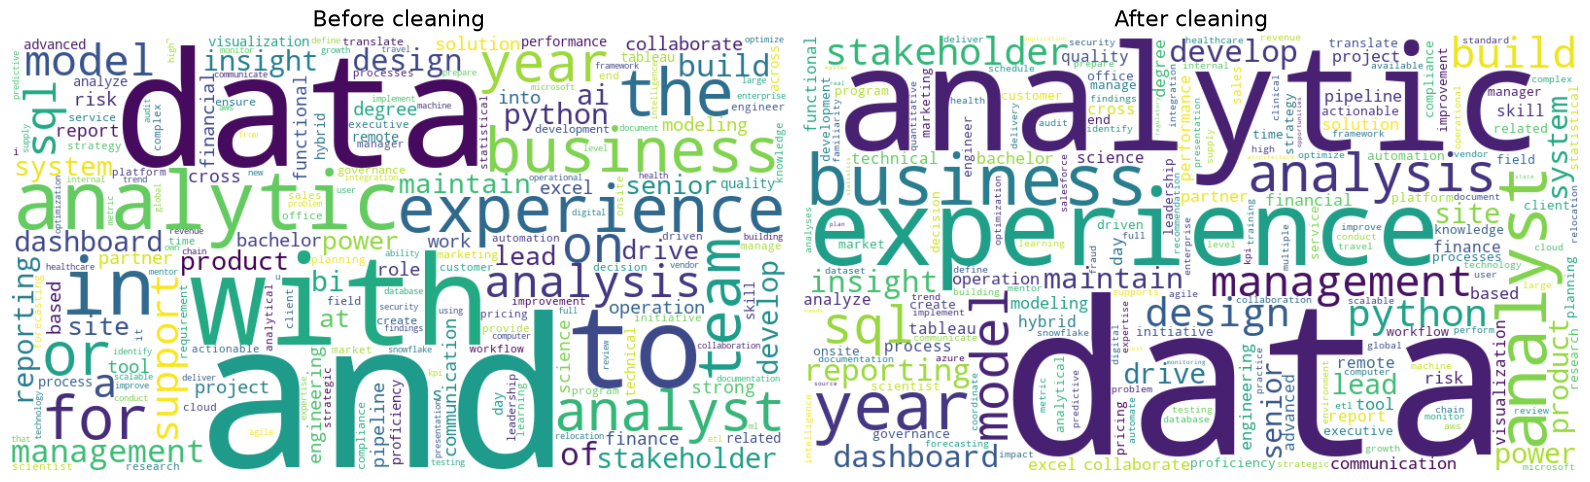

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, text, title in [(axes[0], ' '.join(df['raw_text']), 'Before cleaning'),
                        (axes[1], ' '.join(df['clean_text']), 'After cleaning')]:
    wc = WordCloud(width=800, height=450, background_color='white', colormap='viridis',
                   stopwords=set(), collocations=False, random_state=RANDOM_STATE).generate(text)
    ax.imshow(wc, interpolation='bilinear')
    ax.set_title(title, fontsize=16)
    ax.axis('off')
plt.tight_layout()
plt.show()

Focus area: 282 entry-accessible postings (37% of subset)


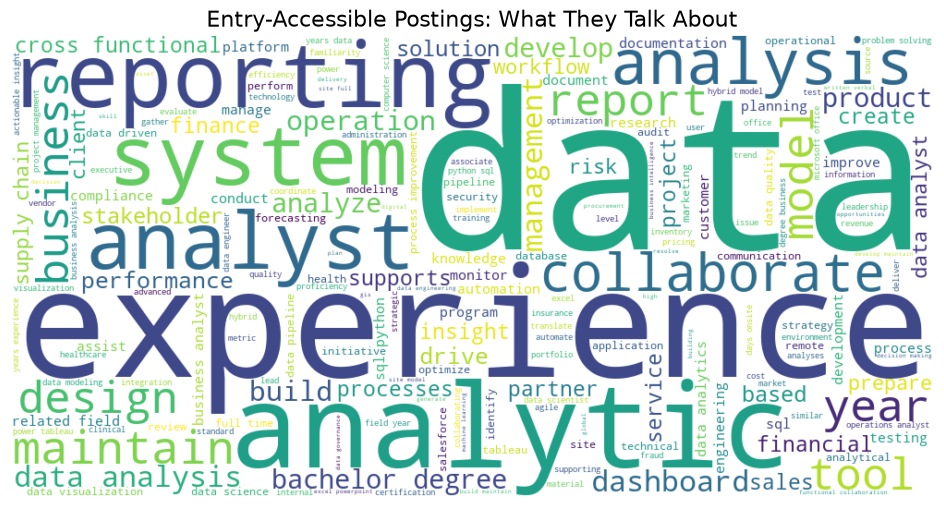

In [10]:
entry = df[df['entry_accessible']]
print(f'Focus area: {len(entry)} entry-accessible postings ({len(entry)/len(df):.0%} of subset)')
ngram_chart(entry['clean_text'], 2, 'Bigram', 'Tealgrn', 'entry-accessible postings')

fig, ax = plt.subplots(figsize=(12, 6))
wc = WordCloud(width=1000, height=500, background_color='white', colormap='viridis',
               collocations=True, random_state=RANDOM_STATE).generate(' '.join(entry['clean_text']))
ax.imshow(wc, interpolation='bilinear')
ax.set_title('Entry-Accessible Postings: What They Talk About', fontsize=16)
ax.axis('off')
plt.show()

## 6. TF-IDF and Cosine Similarity
We turn each posting into a TF-IDF vector (unigrams and bigrams), then score every posting against a **"dream job" profile for our UK graduate**: an early-career data/business analyst role using SQL, Excel, Tableau/Power BI and some Python. We rank only **entry-accessible** postings, since those are the ones a new graduate would actually apply for.

In [11]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

tfidf_vec = TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_df=0.8, max_features=3000)
tfidf = tfidf_vec.fit_transform(df['clean_text'])
print(f'TF-IDF matrix: {tfidf.shape[0]} postings x {tfidf.shape[1]} terms')

DREAM_JOB = clean_text('data analyst business analyst sql excel tableau power bi python dashboards '
                       'reporting stakeholders insights analysis junior graduate')
dream_scores = cosine_similarity(tfidf_vec.transform([DREAM_JOB]), tfidf).ravel()
df['dream_job_similarity'] = dream_scores

top_matches = df[df['entry_accessible']].sort_values('dream_job_similarity', ascending=False).head(10)
print('Top 10 entry-accessible postings closest to our UK-graduate dream-job profile:')
display(top_matches[['title', 'company_name', 'location_raw', 'salary_mid', 'years_required',
                     'dream_job_similarity']].round(3))

labels = [f"{r.title[:35]} ({str(r.company_name)[:18]})" for r in top_matches.itertuples()]
sim_matrix = cosine_similarity(tfidf[top_matches.index])
fig = px.imshow(sim_matrix, x=labels, y=labels, labels=dict(color='Cosine Similarity'),
                title='Similarity Matrix: Our 10 Best-Fit Postings', color_continuous_scale='Viridis')
fig.update_traces(hovertemplate='<b>A:</b> %{y}<br><b>B:</b> %{x}<br><b>Similarity:</b> %{z:.3f}<extra></extra>')
style(fig, width=800, height=800, margin=dict(l=220, r=40, t=80, b=220)).show()

TF-IDF matrix: 753 postings x 3000 terms
Top 10 entry-accessible postings closest to our UK-graduate dream-job profile:


,title,company_name,location_raw,salary_mid,years_required,dream_job_similarity
677,Business Analyst,Boeing,"Everett,WA,United States of America",114000.0,NaN,0.216
450,Technical Data Analyst (Border Security),Navigant,"Washington,DC,US",130500.0,NaN,0.211
464,Analyst – Category & Commercial Analytics,Verde Farms,"Pedricktown,NJ,USA",80000.0,1.0,0.176
375,"BUSINESS ANALYST, INFORMATION TECHNOLOGY",Denver Public Schools,"Denver,CO,United States",NaN,2.0,0.175
535,"Data, Growth & Analytics Intern",EarnIn,"Mountain View,CA,US",72800.0,NaN,0.173
388,Research Data Analyst / Data & Analytics,Children's Hospital & Medical Center,United States,NaN,2.0,0.170
306,Operations Analyst - Customer Service,Uline,"Kenosha,WI,US",NaN,2.0,0.169
437,Data Analyst,Probst Electric,"Sandy Springs,GA,US",75000.0,NaN,0.163
136,BI Analyst,Manhattan Beer Distributors,"Bronx,NY,United States",85000.0,2.0,0.150
719,"Analyst, Data Analytics",LPL Financial,"Fort Mill,SC,United States of America",99392.8,2.0,0.148


## 7. Near-Duplicate Audit
We flag every pair of postings with cosine similarity of **0.95 or higher** and classify it:
* **Multi-location copy:** same company and title in a *different* city. This is a legitimate posting per location, so we keep it.
* **Same-location repeat:** same company, title and city. Likely a true duplicate (for example, posted on two ATS feeds).
* **Template match:** different company or title with near-identical text, such as a staffing agency or boilerplate description.

We **flag but do not delete** anything, as the professor instructed.

In [12]:
full_sim = cosine_similarity(tfidf)
i_idx, j_idx = np.where(np.triu(full_sim, k=1) >= 0.95)
pairs = pd.DataFrame({'a': i_idx, 'b': j_idx, 'similarity': full_sim[i_idx, j_idx]})

def classify_pair(r):
    a, b = df.loc[r.a], df.loc[r.b]
    same_co = a.company_name == b.company_name
    same_title = a.title == b.title
    same_city = a.city == b.city
    if same_co and same_title and not same_city:
        return 'Multi-location copy (keep)'
    if same_co and same_title and same_city:
        return 'Same-location repeat (likely duplicate)'
    return 'Template match (review)'

if len(pairs):
    pairs['type'] = pairs.apply(classify_pair, axis=1)
    pairs['title_a'] = df.loc[pairs.a, 'title'].values
    pairs['company'] = df.loc[pairs.a, 'company_name'].values
    pairs['city_a'] = df.loc[pairs.a, 'city'].values
    pairs['city_b'] = df.loc[pairs.b, 'city'].values
    display(pairs['type'].value_counts().rename('pairs').to_frame())
    display(pairs.sort_values('similarity', ascending=False).head(12)[['title_a', 'company', 'city_a', 'city_b', 'similarity', 'type']].round(3))
else:
    print('No pairs at or above 0.95.')

dup_rows = set(pairs.loc[pairs['type'].str.startswith('Same-location'), 'b']) if len(pairs) else set()
df['likely_duplicate'] = df.index.isin(dup_rows)
print(f"{len(pairs)} near-duplicate pairs; {df['likely_duplicate'].sum()} postings flagged as likely duplicates (kept, but flagged).")

# Context: the closest pairs in the subset, whatever their score
upper = np.triu(full_sim, k=1)
flat = np.argsort(upper, axis=None)[::-1][:8]
closest = pd.DataFrame([(df.loc[a, 'title'], df.loc[a, 'company_name'], df.loc[a, 'city'], df.loc[b, 'title'],
                         df.loc[b, 'company_name'], df.loc[b, 'city'], upper[a, b])
                        for a, b in zip(*np.unravel_index(flat, upper.shape))],
                       columns=['title_a', 'company_a', 'city_a', 'title_b', 'company_b', 'city_b', 'similarity'])
print('\nClosest pairs in the subset (any score):')
display(closest.round(3))

# Multi-location groups found by metadata, even though their text differs slightly
multi = df.groupby(['company_name', 'title']).agg(cities=('city', 'nunique'), postings=('city', 'size'),
                                                  locations=('city', lambda s: ', '.join(sorted(s.unique())[:5])))
multi = multi[multi['cities'] > 1].sort_values('postings', ascending=False)
print(f'\n{len(multi)} company + title combinations are posted in more than one city ({int(multi["postings"].sum())} postings):')
display(multi.head(10))

No pairs at or above 0.95.
0 near-duplicate pairs; 0 postings flagged as likely duplicates (kept, but flagged).

Closest pairs in the subset (any score):


,title_a,company_a,city_a,title_b,company_b,city_b,similarity
0,Finance Operations Analyst - Behavioral Health,University Health Truman Medical Center,Kansas City,Finance Operations Analyst - Behavioral Health,University Health Truman Medical Center,Kansas City,0.909
1,Senior Capital Markets Analyst,Palmetto Clean Technology,Charlotte,Senior Capital Markets Analyst,Palmetto Clean Technology,Charlotte,0.898
2,Lease Administration Analyst,Jones Lang LaSalle,Dallas,Lease Administration Analyst,Jones Lang LaSalle,Dallas,0.886
3,Senior Data Analytics Engineer,Axon,Atlanta,Senior Data Analytics Engineer,Axon,Boston,0.883
4,System Engineer- Enterprise Data Engineer,Esri,Vienna,System Engineer- Enterprise Data Engineer,Esri,Redlands,0.875
5,Senior Data Analytics Engineer,Axon,Atlanta,Senior Data Analytics Engineer,Axon,New York,0.851
6,Sr Associate Data Scientist,"JMP Statistical Discovery,",Cary,Data Scientist (Computer Vision),"JMP Statistical Discovery,",Cary,0.846
7,System Engineer- Enterprise Data Engineer,Esri,St. Louis,System Engineer- Enterprise Data Engineer,Esri,Redlands,0.836



16 company + title combinations are posted in more than one city (44 postings):


cities  \
company_name                       title                                                                       
Axon                               Senior Data Analytics Engineer                                          6   
Booz Allen Hamilton-TEAMS business Data Scientist                                                          4   
                                   Data Engineer                                                           3   
Esri                               System Engineer- Enterprise Data Engineer                               3   
                                   Technical Consultant- Enterprise Data Engineer                          3   
The Wonderful Company              Data Scientist, Modeler                                                 3   
One Park Financial                 Lead Marketing Data Scientist                                           3   
PNC Financial Services             Business Analytics Consultant Senior - Data, Modeling & Analytics       3   
AvePoint                           Channel Analyst                                                         2   
Ameresco                           PV and Energy Storage Remote Operator & Data Analyst                    2   

                                                                                                      postings  \
company_name                       title                                                                         
Axon                               Senior Data Analytics Engineer                                            6   
Booz Allen Hamilton-TEAMS business Data Scientist                                                            4   
                                   Data Engineer                                                             3   
Esri                               System Engineer- Enterprise Data Engineer                                 3   
                                   Technical Consultant- Enterprise Data Engineer                            3   
The Wonderful Company              Data Scientist, Modeler                                                   3   
One Park Financial                 Lead Marketing Data Scientist                                             3   
PNC Financial Services             Business Analytics Consultant Senior - Data, Modeling & Analytics         3   
AvePoint                           Channel Analyst                                                           2   
Ameresco                           PV and Energy Storage Remote Operator & Data Analyst                      2   

                                                                                                                                           locations  
company_name                       title                                                                                                              
Axon                               Senior Data Analytics Engineer                                     Atlanta, Boston, New York, Scottsdale, Seattle  
Booz Allen Hamilton-TEAMS business Data Scientist                                                        Alexandria, Arlington, San Antonio, Suffolk  
                                   Data Engineer                                                                   Arlington, Beavercreek, Chantilly  
Esri                               System Engineer- Enterprise Data Engineer                                             Redlands, St. Louis, Vienna  
                                   Technical Consultant- Enterprise Data Engineer                                        Redlands, St. Louis, Vienna  
The Wonderful Company              Data Scientist, Modeler                                                     Oklahoma, Paragould, West Los Angeles  
One Park Financial                 Lead Marketing Data Scientist                                                       Dallas, Miami, Salt Lake City  
PNC Financial Services       

## 8. K-Means Clustering (Elbow + Silhouette)
We compare inertia (elbow) and silhouette for k = 3-10 on the TF-IDF vectors. **Silhouette will be low.** The professor's full-corpus benchmark is about 0.015 at k = 6. That is normal for sparse text: data and analytics postings share a lot of vocabulary (SQL, stakeholders, dashboards), so the clusters overlap rather than forming clean islands. We choose the final k using both the metrics *and* how interpretable the clusters are for a business audience.

In [13]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

k_range = range(3, 11)
inertias, silhouettes = [], []
for k in k_range:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10).fit(tfidf)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(tfidf, km.labels_, metric='cosine'))

k_metrics = pd.DataFrame({'k': list(k_range), 'inertia': inertias, 'silhouette': silhouettes})
display(k_metrics.round(4))

fig = make_subplots(specs=[[{'secondary_y': True}]])
fig.add_trace(go.Scatter(x=k_metrics.k, y=k_metrics.inertia, name='Inertia (elbow)', mode='lines+markers',
                         line=dict(color='#2980b9'), marker=dict(size=10)), secondary_y=False)
fig.add_trace(go.Scatter(x=k_metrics.k, y=k_metrics.silhouette, name='Silhouette', mode='lines+markers',
                         line=dict(color='#e74c3c'), marker=dict(size=10)), secondary_y=True)
fig.update_yaxes(title_text='Inertia', secondary_y=False)
fig.update_yaxes(title_text='Silhouette (cosine)', secondary_y=True)
fig.update_xaxes(title_text='Number of clusters (k)')
style(fig, title_text='Choosing k: Elbow vs Silhouette').show()

,k,inertia,silhouette
0,3,690.5639,0.0247
1,4,684.9893,0.0236
2,5,679.5410,0.0277
3,6,674.1352,0.0329
4,7,670.0245,0.0341
5,8,664.6307,0.0377
6,9,660.8745,0.0360
7,10,656.9911,0.0383


In [14]:
FINAL_K = 6

kmeans = KMeans(n_clusters=FINAL_K, random_state=RANDOM_STATE, n_init=10).fit(tfidf)
df['cluster'] = kmeans.labels_
terms = np.array(tfidf_vec.get_feature_names_out())
top_terms = {c: terms[kmeans.cluster_centers_[c].argsort()[::-1][:12]].tolist() for c in range(FINAL_K)}

# Business labels: each theme has signal words; a cluster's top terms score points for a theme
# (higher-ranked terms score more), and labels are assigned so every cluster gets its best *unique* theme.
from scipy.optimize import linear_sum_assignment

THEME_RULES = {
    'Data Engineering & Pipelines': {'pipelines', 'pipeline', 'etl', 'engineer', 'engineering', 'cloud', 'aws', 'azure', 'spark', 'databricks', 'snowflake', 'dbt', 'governance', 'architecture'},
    'Data Science & ML Modeling': {'scientist', 'science', 'learning', 'machine', 'models', 'model', 'statistical', 'predictive', 'python'},
    'BI, Dashboards & Visualization': {'dashboards', 'dashboard', 'tableau', 'power', 'visualization', 'looker', 'reporting', 'reports'},
    'Finance, Risk & Compliance': {'financial', 'finance', 'risk', 'compliance', 'fraud', 'credit', 'regulatory', 'audit', 'accounting', 'pricing', 'planning', 'forecasting'},
    'Business Analysis & Requirements': {'requirements', 'process', 'stakeholder', 'stakeholders', 'agile', 'documentation', 'project', 'functional', 'user', 'systems', 'system'},
    'Operations & Supply Chain': {'supply', 'chain', 'procurement', 'inventory', 'logistics', 'sourcing', 'operations', 'vendor'},
    'Marketing, Product & Customer Insights': {'marketing', 'market', 'research', 'customer', 'campaign', 'product', 'growth', 'brand', 'consumer'},
    'AI / GenAI Products': {'genai', 'llm', 'generative', 'agents', 'prompt'},
    'Healthcare & Clinical Data': {'health', 'healthcare', 'clinical', 'patient', 'medical'},
}

def assign_labels(term_lists):
    themes = list(THEME_RULES)
    scores = np.zeros((len(term_lists), len(themes)))
    for i, words in enumerate(term_lists):
        for rank, term in enumerate(words):
            for j, theme in enumerate(themes):
                if set(term.split()) & THEME_RULES[theme]:
                    scores[i, j] += len(words) - rank
    rows, cols = linear_sum_assignment(-scores)
    labels = {}
    for i, j in zip(rows, cols):
        labels[i] = themes[j] if scores[i, j] > 0 else 'Mixed: ' + ', '.join(term_lists[i][:3])
    return labels

cluster_names = {c: f'C{c + 1}: {name}' for c, name in assign_labels([top_terms[c] for c in range(FINAL_K)]).items()}
df['cluster_named'] = df['cluster'].map(cluster_names)

cluster_profile = df.groupby('cluster_named').agg(
    postings=('title', 'size'),
    median_salary=('salary_mid', 'median'),
    entry_accessible_share=('entry_accessible', 'mean'),
    remote_share=('remote_flag', 'mean'),
).round(2)
cluster_profile['top_terms'] = [', '.join(top_terms[c][:8]) for c in range(FINAL_K)]
display(cluster_profile)

pca = PCA(n_components=2, random_state=RANDOM_STATE)
coords = pca.fit_transform(tfidf.toarray())
df['pca_x'], df['pca_y'] = coords[:, 0], coords[:, 1]
fig = px.scatter(df, x='pca_x', y='pca_y', color='cluster_named',
                 title='Segmentation Mapping: 2D K-Means Cluster Projection (PCA)',
                 hover_data=['title', 'company_name', 'salary_mid', 'work_setting'],
                 labels={'pca_x': 'Component 1', 'pca_y': 'Component 2', 'cluster_named': 'Role Segment'},
                 color_discrete_sequence=px.colors.qualitative.Prism)
fig.update_traces(marker=dict(size=7, opacity=0.85, line=dict(width=0.5, color='#ffffff')))
style(fig, height=600).show()
print(f'PCA explains {pca.explained_variance_ratio_.sum():.1%} of TF-IDF variance in 2D: overlap in the plot is expected.')

,postings,median_salary,entry_accessible_share,remote_share,top_terms
cluster_named,,,,,
C1: Business Analysis & Requirements,129,112500.0,0.41,0.10,"business, business analyst, analyst, process, management, analysis, project, agile"
C2: Data Engineering & Pipelines,93,147500.0,0.30,0.23,"pipelines, engineer, data engineer, etl, engineering, aws, sql, python"
"C3: BI, Dashboards & Visualization",310,100250.0,0.43,0.15,"analytics, analyst, reporting, analysis, financial, business, sales, excel"
"C4: Finance, Risk & Compliance",64,113788.5,0.38,0.14,"risk, compliance, fraud, credit, security, management, risk management, analyst"
C5: Data Science & ML Modeling,109,155925.0,0.21,0.10,"scientist, data scientist, python, learning, science, data science, machine, machine learning"
C6: Operations & Supply Chain,48,98200.0,0.46,0.08,"supply, supply chain, chain, procurement, inventory, analytics, sourcing, power"


PCA explains 3.3% of TF-IDF variance in 2D: overlap in the plot is expected.



### K-means interpretation
*Figures quoted are from our run of this notebook.*

**Why k = 6.** Silhouette rises only slowly, from 0.025 at k = 3 to 0.038 at k = 10, with no clear peak. Inertia falls almost in a straight line, with no sharp elbow. Neither metric points to a single "natural" k, which is what the professor told us to expect for sparse text. We chose **k = 6**:
* Silhouette is 0.033, above the professor's full-corpus benchmark of about 0.015, because our subset is more focused.
* Six clusters map one-to-one onto job families a recruiter would recognise.
* Going higher mostly splits the large reporting cluster into fragments too small to profile by metro.

**What low silhouette means.** The clusters overlap: almost every posting shares core vocabulary such as SQL, stakeholders and reporting, so clusters are neighbourhoods with blurry borders, not separate islands. The 2-D PCA plot captures only about 3% of the TF-IDF variance, so the heavy overlap in the picture is expected.

| Cluster | Size | Median salary | Entry-accessible | Read-out |
|---|---|---|---|---|
| BI, Dashboards & Visualization | 310 (41%) | ~$100K | 43% | The core analyst job: reporting, Excel, financial/sales analysis. **Main door in for a graduate.** |
| Business Analysis & Requirements | 129 | ~$113K | 41% | Process, agile, requirements: the "business analyst" track |
| Data Science & ML Modeling | 109 | ~$156K | 21% | Best paid but least accessible |
| Data Engineering & Pipelines | 93 | ~$148K | 30% | ETL, AWS, pipelines; highest remote share (23%) |
| Finance, Risk & Compliance | 64 | ~$114K | 38% | Risk, fraud and credit analytics (banks) |
| Operations & Supply Chain | 48 | ~$98K | 46% | Most accessible, lowest paid |

**Business takeaway:** the entry door is the BI/reporting and business-analysis families. Data science and engineering pay about $50K more but want experience, so they are a *second-job* target rather than a first one.


## 9. LDA Topic Modeling (with pyLDAvis)
LDA is fitted on **raw word counts** (a `CountVectorizer`), not TF-IDF, because LDA's probability model assumes counts.

**Extra filter for topic modeling only:** we drop terms that appear in more than **40% of postings** (`max_df=0.4`). Inside our subset, words like *data, analyst, analytics, business, experience, years* and even *sql* appear in almost every posting. Many of them are the very words we used to select the subset, so they cannot tell topics apart and would otherwise dominate every topic. They stay in the text everywhere else, and years of experience is already captured as a numeric regex feature.

We compare perplexity for 3-10 topics and give every topic a business label.

In [15]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation

count_vec = CountVectorizer(ngram_range=(1, 2), min_df=5, max_df=0.4, max_features=2000)
dtm = count_vec.fit_transform(df['clean_text'])
doc_freq = Counter(w for t in df['clean_text'] for w in set(t.split()))
print('Removed for LDA (in >40% of postings):', ', '.join(w for w, c in doc_freq.most_common(40) if c / len(df) > 0.4))

perplexities = []
for n in range(3, 11):
    lda_n = LatentDirichletAllocation(n_components=n, random_state=RANDOM_STATE, learning_method='batch', max_iter=20)
    lda_n.fit(dtm)
    perplexities.append(lda_n.perplexity(dtm))
display(pd.DataFrame({'topics': range(3, 11), 'perplexity': np.round(perplexities, 1)}).T)
fig = px.line(x=list(range(3, 11)), y=perplexities, markers=True,
              title='LDA: Perplexity by Number of Topics (lower is better, but watch interpretability)',
              labels={'x': 'Number of topics', 'y': 'Perplexity'}, color_discrete_sequence=['#2980b9'])
fig.update_traces(marker=dict(size=10, color='#e74c3c', line=dict(width=2, color='#ffffff')))
style(fig).show()

Removed for LDA (in >40% of postings): data, years, experience, analytics, analyst, business, analysis, site, develop, sql, builds, bachelor, degree, management, based, maintain, collaborate, insights


,0,1,2,3,4,5,6,7
topics,3.0,4.0,5.0,6.0,7.0,8.0,9.0,10.0
perplexity,997.6,997.3,1008.0,995.3,977.2,966.1,969.2,972.9


In [16]:
N_TOPICS = 6

lda = LatentDirichletAllocation(n_components=N_TOPICS, random_state=RANDOM_STATE, learning_method='batch', max_iter=30)
doc_topics = lda.fit_transform(dtm)
vocab = np.array(count_vec.get_feature_names_out())
topic_terms = {t: vocab[lda.components_[t].argsort()[::-1][:12]].tolist() for t in range(N_TOPICS)}

topic_names = {t: f'Topic {t + 1}: {name}' for t, name in assign_labels([topic_terms[t] for t in range(N_TOPICS)]).items()}

topic_table = pd.DataFrame({topic_names[t]: topic_terms[t][:10] for t in range(N_TOPICS)})
display(topic_table)

df['dominant_topic'] = pd.Series(doc_topics.argmax(axis=1)).map(topic_names)
topic_mix = df['dominant_topic'].value_counts().reset_index()
topic_mix.columns = ['Topic', 'Postings']
fig = px.bar(topic_mix, x='Postings', y='Topic', orientation='h', title='Dominant LDA Topic per Posting',
             color='Postings', color_continuous_scale='Tealgrn')
style(fig, height=450, yaxis={'categoryorder': 'total ascending'}, coloraxis_showscale=False,
      margin=dict(l=320, r=40, t=80, b=60)).show()

topic_metro_view = df.groupby('dominant_topic').agg(entry_share=('entry_accessible', 'mean'),
                                                    median_salary=('salary_mid', 'median')).round(2)
display(topic_metro_view)

,Topic 1: Data Engineering & Pipelines,"Topic 2: Marketing, Product & Customer Insights","Topic 3: BI, Dashboards & Visualization",Topic 4: Data Science & ML Modeling,Topic 5: Business Analysis & Requirements,"Topic 6: Finance, Risk & Compliance"
0,pipelines,marketing,dashboards,python,business analyst,excel
1,engineering,research,power,science,process,financial
2,security,market,python,data science,stakeholder,reporting
3,engineer,communication,tableau,learning,system,operations
4,cloud,modeling,visualization,engineering,project,finance
5,etl,model,reporting,scientist,product,risk
6,governance,product,modeling,models,health,sales
7,data engineer,quantitative,data visualization,data scientist,systems,cross
8,quality,senior,tools,model,agile,cross functional
9,aws,growth,models,solutions,solutions,functional


,entry_share,median_salary
dominant_topic,,
Topic 1: Data Engineering & Pipelines,0.30,144750.0
"Topic 2: Marketing, Product & Customer Insights",0.46,102700.0
"Topic 3: BI, Dashboards & Visualization",0.38,118750.0
Topic 4: Data Science & ML Modeling,0.15,171650.0
Topic 5: Business Analysis & Requirements,0.36,109700.0
"Topic 6: Finance, Risk & Compliance",0.48,92500.0


In [17]:
try:
    import pyLDAvis
    import pyLDAvis.lda_model
    pyLDAvis.enable_notebook()
    lda_vis = pyLDAvis.lda_model.prepare(lda, dtm, count_vec, mds='mmds', sort_topics=False)
    pyLDAvis.save_html(lda_vis, 'pyldavis_topics.html')
    print('Interactive pyLDAvis panel below (also saved to pyldavis_topics.html). Topic numbers match the table above.')
    display(lda_vis)
except Exception as exc:
    print(f'pyLDAvis could not render here ({type(exc).__name__}: {exc}). In Colab run `!pip install pyLDAvis` then re-run this cell.')

Interactive pyLDAvis panel below (also saved to pyldavis_topics.html). Topic numbers match the table above.


PreparedData(topic_coordinates=              x         y  topics  cluster       Freq
topic                                                
0      0.087498  0.262914       1        1  11.870330
1     -0.076835 -0.221497       2        1  11.302096
2     -0.228499 -0.009614       3        1  17.659912
3     -0.119947  0.159481       4        1  16.499694
4      0.231340 -0.020052       5        1  15.291780
5      0.106443 -0.171234       6        1  27.376188, topic_info=            Term        Freq       Total Category  logprob  loglift
1107   marketing  247.000000  247.000000  Default  30.0000  30.0000
1317   pipelines  303.000000  303.000000  Default  29.0000  29.0000
1340       power  409.000000  409.000000  Default  28.0000  28.0000
442   dashboards  449.000000  449.000000  Default  27.0000  27.0000
706        excel  361.000000  361.000000  Default  26.0000  26.0000
...          ...         ...         ...      ...      ...      ...
361   compliance  114.053163  251.097758   Topic6  -5.2799   0.5063
442   dashboards  139.221574  449.107540   Topic6  -5.0805   0.1243
96    analytical  104.801978  221.679977   Topic6  -5.3645   0.5463
1340       power  107.133120  409.980131   Topic6  -5.3425  -0.0465
1852       tools  103.975852  369.070095   Topic6  -5.3725   0.0287

[444 rows x 6 columns], token_table=      Topic      Freq        Term
term                             
2         5  0.957662  acceptance
5         1  0.037774  accounting
5         5  0.113321  accounting
5         6  0.856207  accounting
14        2  0.144693  actionable
...     ...       ...         ...
1983      1  0.252469  years data
1983      2  0.037128  years data
1983      3  0.467810  years data
1983      4  0.222767  years data
1983      6  0.022277  years data

[900 rows x 3 columns], R=30, lambda_step=0.01, plot_opts={'xlab': 'PC1', 'ylab': 'PC2'}, topic_order=[1, 2, 3, 4, 5, 6])


### LDA and pyLDAvis interpretation
*Figures quoted are from our run of this notebook.*

**Why 6 topics.** Perplexity moves less than 5% across 3-10 topics (about 966 to 1,008), so it cannot pick a winner. We chose 6 because each topic reads as a clear business theme, and the topics closely mirror the six K-means clusters. Two different methods landing on the same families is good evidence that the families are real.

| Topic | Signature words | Median salary | Entry-accessible |
|---|---|---|---|
| 1. Data Engineering & Pipelines | pipelines, engineering, cloud, ETL, governance, AWS | ~$145K | 30% |
| 2. Marketing, Product & Customer Insights | marketing, research, market, product, growth | ~$103K | 46% |
| 3. BI, Dashboards & Visualization | dashboards, Power BI, Tableau, visualization, reporting | ~$119K | 38% |
| 4. Data Science & ML Modeling | Python, data science, learning, models, scientist | ~$172K | 15% |
| 5. Business Analysis & Requirements | business analyst, process, stakeholder, agile, health | ~$110K | 36% |
| 6. Finance, Risk & Compliance | Excel, financial, reporting, operations, risk, pricing | ~$93K | 48% |

**Reading the pyLDAvis panel.** Circle size is the topic's share of all words; Topic 6 is the largest, at about 27%. Distance between circles shows how different the topics' vocabularies are. In our run the map splits into two neighbourhoods:
* A **technical** side, where Data Engineering, Data Science and BI sit close together.
* A **business-domain** side, where Finance/Risk, Business Analysis and Marketing sit close together.

Data Engineering and Marketing are the furthest apart. Slide λ down to about 0.3-0.5 to see each topic's *distinctive* terms rather than its most frequent ones.

**Business takeaway:** the most accessible topics (Finance/Risk/Operations reporting at 48%, Marketing insights at 46%) are Excel-and-reporting heavy. Python-heavy topics pay more but open fewer doors to graduates.


## 10. Skills Analysis (from the `skills` column)
The `skills` column is pipe-delimited (`SQL|Python|Tableau`). We split it, normalize spelling variants (for example `PowerBI` -> `power bi`, `MS Excel` -> `excel`), then count frequency and **co-occurrence**: which skills are asked for together.

In [18]:
SKILL_SYNONYMS = {
    'powerbi': 'power bi', 'microsoft power bi': 'power bi', 'ms excel': 'excel', 'microsoft excel': 'excel',
    'advanced excel': 'excel', 'excel modeling': 'excel', 'amazon web services': 'aws', 'postgresql': 'sql',
    'mysql': 'sql', 'sql server': 'sql', 't-sql': 'sql', 'data visualisation': 'data visualization',
    'ml': 'machine learning', 'gen ai': 'genai', 'generative ai': 'genai', 'stakeholder communication': 'stakeholder management',
}

def parse_skills(s):
    if not isinstance(s, str):
        return []
    items = [x.strip().lower().replace('‑', '-') for x in s.split('|')]
    return sorted({SKILL_SYNONYMS.get(x, x) for x in items if x})

df['skill_list'] = df['skills'].apply(parse_skills)
has_skills = df['skill_list'].str.len() > 0
print(f"{has_skills.sum()} of {len(df)} postings ({has_skills.mean():.0%}) have a skills list.")

skill_counts = Counter(s for lst in df['skill_list'] for s in lst)
skill_freq = pd.DataFrame(skill_counts.most_common(20), columns=['Skill', 'Postings'])
skill_freq['Share of postings with skills (%)'] = (skill_freq['Postings'] / has_skills.sum() * 100).round(1)
fig = px.bar(skill_freq.sort_values('Postings'), x='Postings', y='Skill', orientation='h',
             title='Top 20 Skills Employers List (skills column)', color='Postings', color_continuous_scale='Mint')
style(fig, height=600, coloraxis_showscale=False).show()

top15 = [s for s, _ in skill_counts.most_common(15)]
co = pd.DataFrame(0, index=top15, columns=top15)
for lst in df['skill_list']:
    present = [s for s in lst if s in top15]
    for a, b in combinations(present, 2):
        co.loc[a, b] += 1
        co.loc[b, a] += 1
fig = px.imshow(co, title='Skill Co-occurrence: How Often Top Skills Are Requested Together',
                color_continuous_scale='Viridis', labels=dict(color='Postings'))
style(fig, width=800, height=750, margin=dict(l=160, r=40, t=80, b=160)).show()

entry_skills = Counter(s for lst in df.loc[df['entry_accessible'], 'skill_list'] for s in lst)
other_skills = Counter(s for lst in df.loc[~df['entry_accessible'], 'skill_list'] for s in lst)
n_entry, n_other = df['entry_accessible'].sum(), (~df['entry_accessible']).sum()
compare = pd.DataFrame({'Skill': top15,
                        'Entry-accessible (%)': [entry_skills[s] / n_entry * 100 for s in top15],
                        'Mid/Senior (%)': [other_skills[s] / n_other * 100 for s in top15]})
fig = px.bar(compare.melt(id_vars='Skill', var_name='Group', value_name='Share (%)'), x='Skill', y='Share (%)',
             color='Group', barmode='group', title='Do Entry-Accessible Roles Ask for Different Skills?',
             color_discrete_sequence=['#16a085', '#2c3e50'])
style(fig, height=500, xaxis_tickangle=35).show()

676 of 753 postings (90%) have a skills list.



**Skills takeaways (our run):**
* **SQL is the universal requirement.** It appears in 48% of postings that have a skills list, and **SQL + Python** is by far the most common pair (205 postings), followed by SQL + Power BI and SQL + Tableau.
* **Entry-accessible roles lean on Excel and reporting.** Excel appears in 29% of entry roles vs 14% of mid/senior roles, and reporting in 15% vs 5%.
* **Senior roles over-index on Python, Snowflake, machine learning and stakeholder management.** Those are the skills to grow into for the next job.


## 11. Geospatial Analytics
### 11a. Matching coordinates to real places
The raw location fields are messy in two different ways:
* **Coordinates are sometimes geocoded to the wrong country.** *San Carlos, CA* lands in Guatemala, and a bare *"US"* lands in France.
* **The `state` column is often wrong while city and coordinates are right.** We found *Tampa, CT*, *Chicago, NY*, *Pittsburgh, WA*, and *Washington, WA* with coordinates in Washington DC.

So we **reverse-geocode every coordinate** with the offline `reverse_geocoder` package (GeoNames places with 1,000+ residents). That gives each posting the nearest real town, its state, and its country, with no API calls. Then we:
1. Mark "Remote", "United States" and state-name-only cities as **not city-level**, because their coordinates are just a state or country centroid.
2. Reject coordinates that fall outside the U.S. (bad geocodes).
3. Measure the **city match rate**: does the posting's city name equal the nearest geocoded place? We report it before and after normalizing names (`NYC` / `New York City` / `Manhattan` -> `New York`, `St.` -> `Saint`, `Ft.` -> `Fort`, `Mt.` -> `Mount`, `Washington, D.C.` -> `Washington`).

In [19]:
import reverse_geocoder as rg

STATE_REF = {
    'AL': ('Alabama', 5157699, 88.823),
    'AK': ('Alaska', 740133, 102.359),
    'AZ': ('Arizona', 7582384, 100.677),
    'AR': ('Arkansas', 3088354, 86.937),
    'CA': ('California', 39431263, 110.720),
    'CO': ('Colorado', 5957493, 103.052),
    'CT': ('Connecticut', 3675069, 103.610),
    'DE': ('Delaware', 1051917, 99.808),
    'DC': ('District of Columbia', 702250, 109.901),
    'FL': ('Florida', 23372215, 103.414),
    'GA': ('Georgia', 11180878, 96.293),
    'HI': ('Hawaii', 1446146, 109.951),
    'ID': ('Idaho', 2001619, 95.494),
    'IL': ('Illinois', 12710158, 99.958),
    'IN': ('Indiana', 6924275, 93.329),
    'IA': ('Iowa', 3241488, 87.762),
    'KS': ('Kansas', 2970606, 90.068),
    'KY': ('Kentucky', 4588372, 90.159),
    'LA': ('Louisiana', 4597740, 88.207),
    'ME': ('Maine', 1405012, 97.050),
    'MD': ('Maryland', 6263220, 104.959),
    'MA': ('Massachusetts', 7136171, 105.757),
    'MI': ('Michigan', 10140459, 96.217),
    'MN': ('Minnesota', 5793151, 98.621),
    'MS': ('Mississippi', 2943045, 86.953),
    'MO': ('Missouri', 6245466, 90.817),
    'MT': ('Montana', 1137233, 94.645),
    'NE': ('Nebraska', 2005465, 90.103),
    'NV': ('Nevada', 3267467, 99.979),
    'NH': ('New Hampshire', 1409032, 104.165),
    'NJ': ('New Jersey', 9500851, 108.805),
    'NM': ('New Mexico', 2130256, 92.212),
    'NY': ('New York', 19867248, 107.921),
    'NC': ('North Carolina', 11046024, 94.326),
    'ND': ('North Dakota', 796568, 88.959),
    'OH': ('Ohio', 11883304, 92.774),
    'OK': ('Oklahoma', 4095393, 87.843),
    'OR': ('Oregon', 4272371, 103.361),
    'PA': ('Pennsylvania', 13078751, 97.572),
    'RI': ('Rhode Island', 1112308, 102.280),
    'SC': ('South Carolina', 5478831, 93.749),
    'SD': ('South Dakota', 924669, 88.586),
    'TN': ('Tennessee', 7227750, 91.870),
    'TX': ('Texas', 31290831, 97.057),
    'UT': ('Utah', 3503613, 98.864),
    'VT': ('Vermont', 648493, 97.958),
    'VA': ('Virginia', 8811195, 101.104),
    'WA': ('Washington', 7958180, 107.013),
    'WV': ('West Virginia', 1769979, 89.497),
    'WI': ('Wisconsin', 5960975, 94.095),
    'WY': ('Wyoming', 587618, 92.691),
}
STATE_CODES = set(STATE_REF)
STATE_NAME_TO_CODE = {v[0]: k for k, v in STATE_REF.items()}
ADMIN1_TO_CODE = {**STATE_NAME_TO_CODE, 'Washington, D.C.': 'DC'}

places = rg.search(list(zip(df['latitude'], df['longitude'])), mode=1, verbose=False)
df['geo_place'] = [p['name'] for p in places]
df['geo_country'] = [p['cc'] for p in places]
df['geo_state'] = pd.Series([ADMIN1_TO_CODE.get(p['admin1']) for p in places], index=df.index).where(df['geo_country'] == 'US')

def norm_city(s):
    s = str(s).lower().strip()
    s = re.sub(r'^(nyc|new york city|manhattan)$', 'new york', s)
    s = re.sub(r'^st\.?\s+', 'saint ', s)
    s = re.sub(r'^ft\.?\s+', 'fort ', s)
    s = re.sub(r'^mt\.?\s+', 'mount ', s)
    s = re.sub(r',?\s*d\.?\s*c\.?$', '', s)
    s = re.sub(r'[^a-z ]', '', s)
    return re.sub(r'\s+', ' ', s).strip()

state_names = {v[0].lower() for v in STATE_REF.values()} - {'new york', 'washington'}
city_level = ~df['city'].fillna('').str.lower().str.strip().isin(['', 'remote', 'united states', 'us', 'usa'] + sorted(state_names))
df['city_clean'] = df['city'].apply(norm_city).str.title().str.replace(r'\bMc(\w)', lambda m: 'Mc' + m.group(1).upper(), regex=True)
df['coord_valid'] = city_level & df['geo_state'].notna() & ~df['remote_flag']

exact = (df['city'].fillna('').str.lower().str.strip() == df['geo_place'].str.lower()) & city_level
normalized = (df['city'].apply(norm_city) == df['geo_place'].apply(norm_city)) & city_level
geo_checks = pd.DataFrame({
    'Check': ['City-level location (not remote / country / state-only)', 'Coordinates resolve to a U.S. state',
              'City name = nearest place (exact text)', 'City name = nearest place (after normalization)',
              'Usable for maps (city-level, in U.S., on-site)'],
    'Postings': [int(city_level.sum()), int((city_level & df['geo_state'].notna()).sum()), int(exact.sum()),
                 int(normalized.sum()), int(df['coord_valid'].sum())],
})
geo_checks['Rate'] = (geo_checks['Postings'] / len(df)).map('{:.1%}'.format)
display(geo_checks)
print('Mismatches are mostly suburbs (coordinates sit nearer a neighbouring town), not wrong locations. Examples:')
display(df.loc[city_level & ~normalized & df['geo_state'].notna(), ['city', 'state', 'geo_place', 'geo_state']].head(8))

,Check,Postings,Rate
0,City-level location (not remote / country / state-only),691,91.8%
1,Coordinates resolve to a U.S. state,688,91.4%
2,City name = nearest place (exact text),392,52.1%
3,City name = nearest place (after normalization),436,57.9%
4,"Usable for maps (city-level, in U.S., on-site)",630,83.7%


Mismatches are mostly suburbs (coordinates sit nearer a neighbouring town), not wrong locations. Examples:


,city,state,geo_place,geo_state
2,Cary,PA,Green Level,NC
9,Jersey City,NJ,Hoboken,NJ
15,Irving,TX,Coppell,TX
17,Franklin,TN,Decherd,TN
19,Franklin,TN,Decherd,TN
24,New York City,NY,Bloomfield,NY
25,New York,NY,Long Island City,NY
35,West Los Angeles,CA,Agoura,CA


### 11b. Fixing the `state` column
When a posting has valid city-level coordinates, its state comes **from the coordinates**. Otherwise we fall back to the raw `state` code, then to a **"City, ST"** pattern in `location_raw`. That pattern is uppercase, after a comma, with word boundaries, which is how we handle ambiguous codes like **IN** and **OR**: the English words "in" and "or" never count. Remote and country-only postings only get a state if `location_raw` names one explicitly.

In [20]:
def infer_state(loc):
    if not isinstance(loc, str):
        return np.nan
    m = re.search(r',\s*([A-Z]{2})\b', loc)
    if m and m.group(1) in STATE_CODES:
        return m.group(1)
    for name, code in sorted(STATE_NAME_TO_CODE.items(), key=lambda kv: -len(kv[0])):
        if re.search(rf'\b{re.escape(name)}\b', loc):
            return code
    return np.nan

raw_state = df['state'].where(df['state'].isin(STATE_CODES))
parsed_state = df['location_raw'].apply(infer_state)
fallback_state = raw_state.fillna(parsed_state).where(city_level, parsed_state)
df['state_clean'] = df['geo_state'].where(df['coord_valid'] | (city_level & df['geo_state'].notna())).fillna(fallback_state)

both = raw_state.notna() & df['geo_state'].notna() & city_level
disagree = both & (raw_state != df['geo_state'])
state_fix = pd.DataFrame({
    'Stage': ['Raw state is a valid U.S. code', 'Raw state DISAGREES with its own coordinates',
              'State filled where raw was missing', 'Final postings with a state', 'No state (remote / country-only)'],
    'Postings': [int(raw_state.notna().sum()), int(disagree.sum()), int((raw_state.isna() & df['state_clean'].notna()).sum()),
                 int(df['state_clean'].notna().sum()), int(df['state_clean'].isna().sum())],
})
display(state_fix)
print(f'{disagree.sum() / both.sum():.0%} of postings with both a raw state and coordinates disagree. Examples:')
display(df.loc[disagree, ['title', 'city', 'state', 'geo_place', 'geo_state']].head(8))

,Stage,Postings
0,Raw state is a valid U.S. code,696
1,Raw state DISAGREES with its own coordinates,133
2,State filled where raw was missing,8
3,Final postings with a state,703
4,No state (remote / country-only),50


20% of postings with both a raw state and coordinates disagree. Examples:


,title,city,state,geo_place,geo_state
2,Financial Analyst,Cary,PA,Green Level,NC
30,"Sr Pricing Analyst, Personal Insurance",Tampa,CT,Tampa,FL
34,Financial Crimes Reporting & Intelligence - Sr. Analyst,Amherst,OH,Amherst,NY
39,Business Analyst,Washington,WA,"Washington, D.C.",DC
44,Operations Research Analyst - TS/SCI,Washington,WA,"Washington, D.C.",DC
49,Senior Principal Risk Analyst (Governance Risk Compliance),Vienna,FL,Vienna,VA
62,Senior Actuarial Data Systems Analyst,Remote Flex - North Carolina,AL,Apex,NC
65,SAP Data Scientist,Washington,WA,"Washington, D.C.",DC


### 11c. Remote and multi-location postings
* **Remote postings** are kept for the text, skills, clustering and salary analysis, but **excluded from the maps**: a remote job has no meaningful metro. They are reported as their own group in the scorecard section.
* **Multi-location postings** (same company and title in several cities) are kept as one posting per city. The near-duplicate audit in Section 7 showed they are legitimate separate openings, and they genuinely add hiring volume to each metro.

In [21]:
geo = df[df['coord_valid']].copy()
print(f'{len(geo)} on-site postings with valid city-level coordinates are used for maps.')

state_agg = df.dropna(subset=['state_clean']).loc[~df['remote_flag']].groupby('state_clean').agg(
    postings=('title', 'size'), disclosed=('salary_disclosed', 'sum'), median_salary=('salary_mid', 'median'),
    disclosure_rate=('salary_disclosed', 'mean'), entry_share=('entry_accessible', 'mean')).reset_index()
state_agg['state_name'] = state_agg['state_clean'].map(lambda c: STATE_REF[c][0])

fig = px.choropleth(state_agg, locations='state_clean', locationmode='USA-states', scope='usa', color='postings',
                    hover_name='state_name', color_continuous_scale='Viridis',
                    title='Data & Analytics Postings by State (on-site / hybrid)', labels={'postings': 'Postings'})
style(fig, height=520).show()

city_agg = geo.groupby(['city_clean', 'state_clean']).agg(
    postings=('title', 'size'), lat=('latitude', 'median'), lon=('longitude', 'median'),
    median_salary=('salary_mid', 'median'), entry_share=('entry_accessible', 'mean')).reset_index()
city_agg['label'] = city_agg['city_clean'] + ', ' + city_agg['state_clean']
fig = px.scatter_geo(city_agg, lat='lat', lon='lon', size='postings', color='median_salary', scope='usa',
                     hover_name='label', hover_data={'postings': True, 'entry_share': ':.0%', 'lat': False, 'lon': False},
                     color_continuous_scale='Viridis', size_max=40,
                     title='City Bubble Map: Posting Volume (size) and Median Salary (color)',
                     labels={'median_salary': 'Median salary ($)'})
style(fig, height=560).show()

630 on-site postings with valid city-level coordinates are used for maps.


In [22]:
fig = px.choropleth(state_agg, locations='state_clean', locationmode='USA-states', scope='usa',
                    color='disclosure_rate', hover_name='state_name', range_color=(0, 1),
                    color_continuous_scale='Tealgrn', title='Salary Disclosure Rate by State',
                    hover_data={'postings': True, 'disclosure_rate': ':.0%'}, labels={'disclosure_rate': 'Disclosed'})
style(fig, height=520).show()

sal_states = state_agg[state_agg['disclosed'] >= 5]
fig = px.choropleth(sal_states, locations='state_clean', locationmode='USA-states', scope='usa',
                    color='median_salary', hover_name='state_name', color_continuous_scale='Viridis',
                    title='Median Disclosed Salary by State (states with 5+ disclosed salaries)',
                    hover_data={'disclosed': True}, labels={'median_salary': 'Median salary ($)'})
style(fig, height=520).show()

In [23]:
MAP_SKILLS = ['SQL', 'Python', 'Excel', 'Tableau', 'Power BI']
skill_state = df.dropna(subset=['state_clean']).loc[~df['remote_flag']]
skill_state = skill_state.groupby('state_clean').filter(lambda g: len(g) >= 8)
skill_map = skill_state.groupby('state_clean')[[f'skill_{s}' for s in MAP_SKILLS]].mean().reset_index()
skill_map = skill_map.melt(id_vars='state_clean', var_name='skill', value_name='share')
skill_map['skill'] = skill_map['skill'].str.replace('skill_', '', regex=False)
skill_map['share'] = (skill_map['share'] * 100).round(1)
fig = px.choropleth(skill_map, locations='state_clean', locationmode='USA-states', scope='usa', color='share',
                    animation_frame='skill', range_color=(0, 100), color_continuous_scale='Viridis',
                    title='Skill-Share Map: % of Postings Asking for Each Tool (use the slider; states with 8+ postings)',
                    labels={'share': '% of postings'})
style(fig, height=560).show()

### 11d. DBSCAN spatial clusters = our "metro areas"
City names alone split metros apart: McLean and Arlington are really the Washington DC metro, and Jersey City is the New York metro. We run **DBSCAN** with the haversine distance on the validated coordinates. Postings within **35 km** of each other chain into one cluster, and a cluster needs at least **5** postings. Each cluster is named after the nearest major metro (within 80 km of the cluster's median point). Points that join no cluster are "noise": small or isolated markets.

In [24]:
from sklearn.cluster import DBSCAN

EPS_KM, MIN_SAMPLES = 35, 5
db = DBSCAN(eps=EPS_KM / 6371.0, min_samples=MIN_SAMPLES, metric='haversine')
geo['metro_id'] = db.fit_predict(np.radians(geo[['latitude', 'longitude']].values))

# Name each cluster after the nearest major metro (principal-city coordinates), so suburbs such as
# McLean or Glendale are labelled by the metro a job seeker would recognise.
METRO_ANCHORS = [
    ('New York', 40.71, -74.01), ('Los Angeles', 34.05, -118.24), ('Chicago', 41.88, -87.63),
    ('Dallas-Fort Worth', 32.78, -96.80), ('Houston', 29.76, -95.37), ('Washington DC', 38.91, -77.04),
    ('Philadelphia-Wilmington', 39.95, -75.17), ('Philadelphia-Wilmington', 39.74, -75.55), ('Miami', 25.76, -80.19),
    ('Atlanta', 33.75, -84.39), ('Boston', 42.36, -71.06), ('Phoenix', 33.45, -112.07),
    ('San Francisco Bay Area', 37.77, -122.42), ('San Francisco Bay Area', 37.34, -121.89), ('Detroit', 42.33, -83.05),
    ('Seattle', 47.61, -122.33), ('Minneapolis-St. Paul', 44.98, -93.27), ('San Diego', 32.72, -117.16),
    ('Tampa', 27.95, -82.46), ('Denver', 39.74, -104.99), ('Baltimore', 39.29, -76.61), ('St. Louis', 38.63, -90.20),
    ('Orlando', 28.54, -81.38), ('Charlotte', 35.23, -80.84), ('San Antonio', 29.42, -98.49), ('Portland', 45.52, -122.68),
    ('Sacramento', 38.58, -121.49), ('Pittsburgh', 40.44, -80.00), ('Austin', 30.27, -97.74), ('Las Vegas', 36.17, -115.14),
    ('Cincinnati', 39.10, -84.51), ('Kansas City', 39.10, -94.58), ('Columbus', 39.96, -83.00), ('Indianapolis', 39.77, -86.16),
    ('Cleveland', 41.50, -81.69), ('Nashville', 36.16, -86.78), ('Raleigh-Durham', 35.78, -78.64),
    ('Salt Lake City', 40.76, -111.89), ('Richmond', 37.54, -77.44), ('Milwaukee', 43.04, -87.91),
    ('Jacksonville', 30.33, -81.66), ('Hartford', 41.76, -72.68), ('Louisville', 38.25, -85.76), ('Madison', 43.07, -89.40),
    ('Des Moines', 41.59, -93.62), ('Omaha', 41.26, -95.93), ('Boise', 43.62, -116.20), ('Providence', 41.82, -71.41),
    ('Birmingham', 33.52, -86.80), ('Memphis', 35.15, -90.05), ('Oklahoma City', 35.47, -97.52),
    ('Albuquerque', 35.08, -106.65), ('Buffalo', 42.89, -78.88), ('Greenville SC', 34.85, -82.40),
    ('Huntsville', 34.73, -86.59), ('Honolulu', 21.31, -157.86),
]

def haversine_km(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 6371 * 2 * np.arcsin(np.sqrt(a))

metro_names, metro_members = {}, {}
for mid, g in geo[geo['metro_id'] >= 0].groupby('metro_id'):
    lat, lon = g['latitude'].median(), g['longitude'].median()
    anchor, km = min(((n, haversine_km(lat, lon, alat, alon)) for n, alat, alon in METRO_ANCHORS), key=lambda x: x[1])
    top_city = g.groupby(['city_clean', 'state_clean']).size().idxmax()
    name = f'{anchor} metro' if km <= 80 else f'{top_city[0]}, {top_city[1]} area'
    if name in metro_names.values():
        name = f'{name} ({top_city[0]})'
    metro_names[mid] = name
    metro_members[name] = ', '.join(g['city_clean'].value_counts().head(4).index)
geo['metro'] = geo['metro_id'].map(metro_names).fillna('Noise / small market')
df['metro'] = geo['metro'].reindex(df.index)

print(f"DBSCAN found {len(metro_names)} metro clusters; {(geo['metro_id'] == -1).sum()} postings are noise (small/isolated markets).")
metro_counts = geo['metro'].value_counts().rename('postings').to_frame()
metro_counts['largest cities in cluster'] = metro_counts.index.map(metro_members).fillna('')
display(metro_counts.head(16))

fig = px.scatter_geo(geo, lat='latitude', lon='longitude', color='metro', scope='usa',
                     hover_name='title', hover_data={'company_name': True, 'city_clean': True, 'latitude': False, 'longitude': False},
                     title=f'DBSCAN Spatial Clusters (eps = {EPS_KM} km, min_samples = {MIN_SAMPLES})',
                     color_discrete_sequence=px.colors.qualitative.Prism + px.colors.qualitative.Safe)
fig.for_each_trace(lambda t: t.update(marker=dict(color='#bdc3c7', size=5)) if t.name == 'Noise / small market' else t.update(marker=dict(size=8)))
style(fig, height=600).show()

DBSCAN found 25 metro clusters; 144 postings are noise (small/isolated markets).


,postings,largest cities in cluster
metro,,
Noise / small market,144,
New York metro,87,"New York, Jersey City, Bronx, Rahway"
Washington DC metro,63,"Washington, McLean, Vienna, Arlington"
Chicago metro,44,"Chicago, Pleasant Prairie, Merrillville, Shiloh"
San Francisco Bay Area metro,33,"San Francisco, San Jose, Mountain View, South San Francisco"
Dallas-Fort Worth metro,26,"Dallas, Irving, Plano, Coppell"
Boston metro,24,"Boston, Somerville, Billerica, Stoughton"
Atlanta metro,23,"Atlanta, Alpharetta, Forest Park, Duluth"
Seattle metro,22,"Seattle, Bellevue, Redmond, Everett"


## 12. Normalized Economic Measures
Raw counts favour big states, and raw salaries favour expensive states. We use two adjustments:
* **Jobs per million residents:** postings / Census 2024 state population x 1,000,000 ([Census NST-EST2024](https://www2.census.gov/programs-surveys/popest/datasets/2020-2024/state/totals/)).
* **Cost-of-living-adjusted salary:** median salary / (state RPP / 100), using BEA **Regional Price Parities, 2024, all items** (U.S. = 100) ([BEA SARPP](https://apps.bea.gov/regional/zip/SARPP.zip)). A $100K salary in a state with RPP 110 buys what $90.9K buys in an average state.

Both reference tables are embedded in Section 11a, so the notebook runs without network access.

In [25]:
state_agg['population'] = state_agg['state_clean'].map(lambda c: STATE_REF[c][1])
state_agg['rpp'] = state_agg['state_clean'].map(lambda c: STATE_REF[c][2])
state_agg['jobs_per_million'] = state_agg['postings'] / state_agg['population'] * 1e6
state_agg['adj_salary'] = state_agg['median_salary'].where(state_agg['disclosed'] >= 5) / (state_agg['rpp'] / 100)

fig = px.choropleth(state_agg, locations='state_clean', locationmode='USA-states', scope='usa',
                    color='jobs_per_million', hover_name='state_name', color_continuous_scale='Viridis',
                    title='Normalized Demand: Data & Analytics Postings per Million Residents',
                    hover_data={'postings': True, 'jobs_per_million': ':.1f'}, labels={'jobs_per_million': 'Per million'})
style(fig, height=520).show()

fig = px.choropleth(state_agg.dropna(subset=['adj_salary']), locations='state_clean', locationmode='USA-states',
                    scope='usa', color='adj_salary', hover_name='state_name', color_continuous_scale='Viridis',
                    title='Cost-of-Living-Adjusted Median Salary (BEA RPP 2024)',
                    hover_data={'median_salary': ':$,.0f', 'rpp': True}, labels={'adj_salary': 'Adjusted salary ($)'})
style(fig, height=520).show()

top_states = state_agg.dropna(subset=['adj_salary']).sort_values('jobs_per_million', ascending=False)
fig = px.scatter(top_states, x='jobs_per_million', y='adj_salary', size='postings', text='state_clean',
                 color='entry_share', color_continuous_scale='Tealgrn',
                 title='States: Demand per Capita vs Purchasing-Power Salary (bubble = postings)',
                 labels={'jobs_per_million': 'Postings per million residents', 'adj_salary': 'RPP-adjusted median salary ($)',
                         'entry_share': 'Entry-accessible share'})
fig.update_traces(textposition='top center')
style(fig, height=600, yaxis_tickformat='$,.0f').show()

display(state_agg.sort_values('postings', ascending=False).head(12)[
    ['state_name', 'postings', 'jobs_per_million', 'median_salary', 'rpp', 'adj_salary', 'entry_share', 'disclosure_rate']].round(2))

,state_name,postings,jobs_per_million,median_salary,rpp,adj_salary,entry_share,disclosure_rate
30,New York,80,4.03,115000.00,107.92,106559.43,0.39,0.88
4,California,63,1.60,156800.00,110.72,141618.50,0.37,0.89
38,Texas,59,1.89,123795.00,97.06,127548.76,0.44,0.46
40,Virginia,41,4.65,126775.00,101.10,125390.69,0.49,0.63
13,Illinois,35,2.75,126502.50,99.96,126555.65,0.23,0.86
10,Georgia,24,2.15,84000.00,96.29,87233.76,0.38,0.29
18,Massachusetts,24,3.36,120400.00,105.76,113845.89,0.29,0.83
24,North Carolina,24,2.17,93298.75,94.33,98910.96,0.38,0.33
41,Washington,22,2.76,173375.00,107.01,162013.03,0.23,0.73
34,Pennsylvania,22,1.68,100500.00,97.57,103000.86,0.27,0.41



**Geography takeaways (our run):**
* **Per capita, demand concentrates around Washington DC.** DC has about 23 postings per million residents (a small population with many federal and contractor roles), followed by Delaware, Virginia and New York, at roughly 4-7 per million. Arkansas punches above its size at about 3.6 per million, and Walmart accounts for 6 of its 11 on-site postings.
* **Cost of living reshuffles salaries.** After BEA price-parity adjustment, Washington State (~$162K) and California (~$142K) still lead, while Georgia (~$87K) and Florida (~$91K) sit at the bottom.
* **Disclosure follows pay-transparency laws.** New Jersey, California, New York and Illinois disclose salary in 86-95% of postings, against only 29-46% in Georgia, North Carolina, Pennsylvania and Texas. Salary comparisons are therefore much more reliable for some states than others.
* **The skill mix varies by state.** SQL appears in 68-75% of postings in Georgia, Colorado and Virginia, but under 30% in Minnesota, Arkansas and North Carolina.


## 13. Metro Scorecard, Summary and Recommendations
**How we define "best combination"** for each DBSCAN metro with at least 10 postings and at least 3 disclosed salaries:

| Component | Measure | Why |
|---|---|---|
| Volume | log(postings), scaled 0-1 | More openings = more shots on goal; the log stops New York from swamping everything |
| Salary | median disclosed salary / (state RPP / 100), scaled 0-1 | What the pay is actually worth locally |
| Accessibility | share of **UK-accessible** postings (entry-accessible **and** no clearance / U.S.-citizenship requirement), scaled 0-1 | How many roles *our* graduate can realistically get |

**Composite score = simple average of the three.** We use equal weights so the ranking is transparent and easy to challenge, and we test other weightings below. Set `USE_UK_ELIGIBILITY = False` to score with the plain entry-accessible share instead and see how the ranking changes for a U.S. citizen.

In [26]:
MIN_METRO = 10
USE_UK_ELIGIBILITY = True
ACCESS_COL = 'uk_accessible' if USE_UK_ELIGIBILITY else 'entry_accessible'

metro_df = geo[geo['metro_id'] >= 0].groupby('metro').agg(
    postings=('title', 'size'), disclosed=('salary_disclosed', 'sum'), median_salary=('salary_mid', 'median'),
    entry_share=('entry_accessible', 'mean'), clearance_share=('clearance_or_citizenship', 'mean'),
    access_share=(ACCESS_COL, 'mean'), access_count=(ACCESS_COL, 'sum'), state=('state_clean', lambda s: s.mode().iat[0])).reset_index()
metro_df = metro_df[(metro_df['postings'] >= MIN_METRO) & (metro_df['disclosed'] >= 3)].copy()
metro_df['rpp'] = metro_df['state'].map(lambda c: STATE_REF[c][2])
metro_df['adj_salary'] = metro_df['median_salary'] / (metro_df['rpp'] / 100)

minmax = lambda s: (s - s.min()) / (s.max() - s.min()) if s.max() > s.min() else s * 0
metro_df['Volume'] = minmax(np.log1p(metro_df['postings']))
metro_df['Salary'] = minmax(metro_df['adj_salary'])
metro_df['Accessibility'] = minmax(metro_df['access_share'])
metro_df['composite'] = metro_df[['Volume', 'Salary', 'Accessibility']].mean(axis=1)
metro_df = metro_df.sort_values('composite', ascending=False).reset_index(drop=True)

display(metro_df[['metro', 'postings', 'median_salary', 'rpp', 'adj_salary', 'entry_share', 'clearance_share', 'access_share', 'access_count', 'composite']].round(2))

stack = metro_df.melt(id_vars='metro', value_vars=['Volume', 'Salary', 'Accessibility'], var_name='Component', value_name='Score')
stack['Score'] = stack['Score'] / 3
fig = px.bar(stack, x='Score', y='metro', color='Component', orientation='h',
             title='Metro Scorecard: Volume + Adjusted Salary + Accessibility',
             color_discrete_sequence=['#2c3e50', '#2980b9', '#16a085'], labels={'metro': ''})
style(fig, height=max(450, 45 * len(metro_df)), yaxis={'categoryorder': 'total ascending'}, barmode='stack').show()

remote = df[df['remote_flag']]
print(f"Remote group (not a metro): {len(remote)} postings, median salary ${remote['salary_mid'].median():,.0f}, "
      f"{remote['entry_accessible'].mean():.0%} entry-accessible.")

# Sensitivity check: does the top 3 survive if one component is weighted double?
weight_sets = {'Equal (our choice)': (1, 1, 1), 'Volume x2': (2, 1, 1), 'Salary x2': (1, 2, 1), 'Accessibility x2': (1, 1, 2)}
sensitivity = {}
for label, (wv, ws, wa) in weight_sets.items():
    score = (wv * metro_df['Volume'] + ws * metro_df['Salary'] + wa * metro_df['Accessibility']) / (wv + ws + wa)
    sensitivity[label] = ', '.join(metro_df.assign(s=score).nlargest(3, 's')['metro'].str.replace(' metro', ''))
print('Weight sensitivity: top 3 metros under different weightings')
display(pd.DataFrame.from_dict(sensitivity, orient='index', columns=['Top 3 metros']))

,metro,postings,median_salary,rpp,adj_salary,entry_share,clearance_share,access_share,access_count,composite
0,San Francisco Bay Area metro,33,184500.0,110.72,166636.56,0.30,0.00,0.30,10,0.64
1,New York metro,87,121000.0,107.92,112119.05,0.37,0.01,0.37,32,0.60
2,Washington DC metro,63,125900.0,101.10,124525.24,0.43,0.41,0.22,14,0.51
3,Seattle metro,22,173375.0,107.01,162013.03,0.23,0.00,0.23,5,0.51
4,Austin metro,11,118750.0,97.06,122350.78,0.64,0.00,0.64,7,0.49
5,Chicago metro,44,122000.0,99.96,122051.26,0.23,0.05,0.20,9,0.43
6,Dallas-Fort Worth metro,26,104802.5,97.06,107980.36,0.38,0.00,0.38,10,0.40
7,Charlotte metro,13,99446.4,94.33,105428.41,0.46,0.00,0.46,6,0.34
8,Boston metro,24,121750.0,105.76,115122.40,0.29,0.08,0.25,6,0.34
9,Minneapolis-St. Paul metro,10,131500.0,98.62,133338.74,0.30,0.00,0.30,3,0.31


Remote group (not a metro): 105 postings, median salary $109,400, 41% entry-accessible.
Weight sensitivity: top 3 metros under different weightings


,Top 3 metros
Equal (our choice),"San Francisco Bay Area, New York, Washington DC"
Volume x2,"New York, San Francisco Bay Area, Washington DC"
Salary x2,"San Francisco Bay Area, Seattle, New York"
Accessibility x2,"Austin, New York, San Francisco Bay Area"


In [27]:
top3 = metro_df.head(3)
rec_rows = []
for r in top3.itertuples():
    members = geo[geo['metro'] == r.metro]
    skills = Counter(s for lst in df.loc[members.index, 'skill_list'] for s in lst).most_common(6)
    rec_rows.append({
        'Rank': len(rec_rows) + 1, 'Metro': r.metro, 'Postings': r.postings,
        'Median salary': f'${r.median_salary:,.0f}', 'RPP-adjusted': f'${r.adj_salary:,.0f}',
        'Entry-accessible': f'{r.entry_share:.0%}', 'Needs clearance / citizenship': f'{r.clearance_share:.0%}',
        'UK-accessible': f'{r.access_share:.0%} ({int(r.access_count)} postings)', 'Top skills asked for': ', '.join(s for s, _ in skills),
        'Example UK-accessible roles': '; '.join(t[:45] for t in members.loc[members['uk_accessible'], 'title'].value_counts().head(3).index),
    })
recommendations = pd.DataFrame(rec_rows)
display(recommendations)

build_skills = Counter(s for lst in df.loc[df['uk_accessible'], 'skill_list'] for s in lst).most_common(8)
print('Skills to build (most requested in UK-accessible postings):', ', '.join(s for s, _ in build_skills))

,Rank,Metro,Postings,Median salary,RPP-adjusted,Entry-accessible,Needs clearance / citizenship,UK-accessible,Top skills asked for,Example UK-accessible roles
0,1,San Francisco Bay Area metro,33,"$184,500","$166,637",30%,0%,30% (10 postings),"sql, python, data visualization, tableau, snowflake, looker",Data Analytics Engineer; Business Analyst Intern; Business Analyst
1,2,New York metro,87,"$121,000","$112,119",37%,1%,37% (32 postings),"sql, data analysis, python, excel, tableau, stakeholder management","Wealth Management Strategic Solutions Product; Systems and Data Operations Analyst; Coordinator,..."
2,3,Washington DC metro,63,"$125,900","$124,525",43%,41%,22% (14 postings),"sql, python, data visualization, tableau, machine learning, excel",Technology Product Analyst; Data Analyst (Data Quality); Cyber Operations Analyst


Skills to build (most requested in UK-accessible postings): sql, excel, data analysis, python, power bi, tableau, reporting, data visualization


In [28]:
headline = pd.DataFrame({
    'Metric': ['Subset size (postings)', 'Entry-accessible share', 'UK-accessible share', 'Salary disclosed', 'Median disclosed salary',
               'Remote share', 'Metros scored', 'City name match rate (normalized)', 'Postings usable on maps'],
    'Value': [f'{len(df):,}', f"{df['entry_accessible'].mean():.0%}", f"{df['uk_accessible'].mean():.0%}", f"{df['salary_disclosed'].mean():.0%}",
              f"${df['salary_mid'].median():,.0f}", f"{df['remote_flag'].mean():.0%}", f'{len(metro_df)}',
              f'{normalized.mean():.0%}', f"{df['coord_valid'].mean():.0%}"],
})
display(headline)

fig = make_subplots(rows=2, cols=2, specs=[[{'type': 'domain'}, {'type': 'domain'}], [{'type': 'domain'}, {'type': 'domain'}]])
fig.add_trace(go.Indicator(mode='number', value=len(df), title=dict(text='Postings Analyzed')), row=1, col=1)
fig.add_trace(go.Indicator(mode='number', value=df['entry_accessible'].mean() * 100, number={'suffix': '%', 'valueformat': '.0f'},
                           title=dict(text='Entry-Accessible')), row=1, col=2)
fig.add_trace(go.Indicator(mode='number', value=df['salary_mid'].median(), number={'prefix': '$', 'valueformat': ',.0f'},
                           title=dict(text='Median Salary')), row=2, col=1)
fig.add_trace(go.Indicator(mode='number', value=top3['adj_salary'].iloc[0], number={'prefix': '$', 'valueformat': ',.0f'},
                           title=dict(text=f"#1 Metro Adj. Salary ({top3['metro'].iloc[0].replace(' metro', '')})")), row=2, col=2)
style(fig, height=600, title_text='Executive Summary Dashboard')
fig.show()

,Metric,Value
0,Subset size (postings),753
1,Entry-accessible share,37%
2,UK-accessible share,34%
3,Salary disclosed,64%
4,Median disclosed salary,"$117,500"
5,Remote share,14%
6,Metros scored,14
7,City name match rate (normalized),58%
8,Postings usable on maps,84%



### Recommendations for our UK graduate
*Figures quoted are from our run of this notebook.*

The composite score ranks **San Francisco Bay Area (0.64), New York (0.60) and Washington DC (0.51)** as the top three. San Francisco and New York stay in the top three under **every** weighting we tested.

1. **New York metro: apply here first.** The score puts it second, but it has the **most UK-accessible openings in absolute terms (32, about 3x San Francisco's 10)**, almost no clearance or citizenship barriers (1%), and a median salary of about $121K ($112K after cost of living). The skills to show are SQL, data analysis, Python, Excel, Tableau and stakeholder management. Employers are a mix of banks (Morgan Stanley, JPMorgan Chase, Citigroup), healthcare (Charlie Health) and the public sector (NYC Department of City Planning).
2. **San Francisco Bay Area: the best pay.** It has the highest purchasing-power salary (about $185K median, $167K adjusted) and no clearance barriers, but only 33 postings and 30% UK-accessible, so it is competitive. Employers are tech companies (Adobe, Google, Salesforce, OpenAI), and the modern data stack shows up: SQL, Python, Tableau, **Snowflake and Looker**.
3. **Washington DC metro: big, but filter carefully.** On paper it has 63 postings and the highest entry-accessible share among the large metros (43%). However, **41% of its postings require a security clearance or U.S. citizenship**, which cuts what a UK graduate can actually apply for to 22% (14 postings). Federal contractors such as Booz Allen Hamilton dominate the cleared roles. The UK-accessible openings come from employers such as Navy Federal, PNC and RiskSpan.

**Runners-up:** **Austin** is the most accessible metro (64% UK-accessible, about $122K adjusted) but small, with 11 postings. **Seattle** pays well (about $162K adjusted) but only 23% of its roles are UK-accessible. **Remote** roles (105 postings, $109K median, 41% entry-accessible) are worth applying to, but U.S. remote jobs still normally require U.S. work authorization.

**Skills to build first:** SQL, Excel, data analysis, Python, Power BI or Tableau, and reporting. These are the most requested skills in UK-accessible postings. **Next:** Snowflake, machine learning and stakeholder management, which separate mid/senior roles from entry roles.


## 14. Limitations and Sampling Bias
* **Derived description text:** `description_text` is a NextGig-generated summary, not the employer's full ad. N-grams, TF-IDF, clusters and topics describe that summary, and the regex features (years, urgency, salary-in-text) can miss details that were in the original ad.
* **Incomplete salary data:** about a third of postings disclose no usable salary, and disclosure is not random. States with pay-transparency laws (CA, NY, WA, CO) disclose more, which pulls their salaries into view and leaves low-disclosure states under-measured.
* **Postings are not hires:** volume measures advertising, not actual hiring. One opening can be posted in several places (see Section 7), and evergreen ads inflate some employers.
* **Clusters and topics are model constructs:** low silhouette means overlapping clusters, and LDA topics shift with k, random seed and stopwords. The business labels are our interpretation.
* **Snapshot and source bias:** one summer-2026 snapshot drawn only from ATS feeds NextGig covers. Small employers and companies on other platforms are under-represented, and seasonality is invisible.
* **Geography:** the coordinates had geocoding errors that we corrected only partly. RPP is state-level, so a metro inherits its state's price level (New York City is pricier than New York State's average). Remote postings are excluded from metro rankings.
* **Entry-level rule:** only some postings state years of experience, so "no years stated" is treated as accessible. That is optimistic.
* **UK-graduate persona:** visa sponsorship and work authorization, the biggest real-world barrier, are almost never mentioned in the text, so this notebook cannot rank employers on sponsorship. The clearance/citizenship flag only catches postings that *say* so; some federal-contractor roles may require it without stating it.

## 15. Industry Question: Who Is Investing Most in Data, Analytics and AI?
Here we use **all U.S. postings** (not just our subset), because the question is about the whole market. We keep three things strictly separate:
1. **Observed facts:** counts straight from the data.
2. **Inferences:** derived labels, such as industry inferred from company names when `company_industry` is blank.
3. **Theory:** our explanation of *why*. It is clearly marked as speculation.

In [29]:
us_all = us.copy()
ai_text = (us_all['title'].fillna('') + ' ' + us_all['skills'].fillna('') + ' ' + us_all['description_text'].fillna(''))
us_all['ai_related'] = ai_text.str.contains(
    r'\bai\b|artificial intelligence|machine learning|\bml\b|genai|generative ai|\bllms?\b|large language model',
    case=False, regex=True)
us_all['in_subset'] = us_all.index.isin(us[title_mask].index)

employer = us_all.groupby('company_name').agg(postings=('title', 'size'), ai_postings=('ai_related', 'sum'),
                                              analytics_postings=('in_subset', 'sum')).reset_index()
employer['ai_share'] = employer['ai_postings'] / employer['postings']
top_emp = employer.sort_values('postings', ascending=False).head(15)
print('OBSERVED: top 15 employers by total postings')
display(top_emp.round(2))

fig = px.bar(top_emp.sort_values('postings'), x=['ai_postings', 'analytics_postings'], y='company_name', orientation='h',
             barmode='group', title='Observed: Top Employers by Postings, AI-Related vs Data & Analytics',
             labels={'value': 'Postings', 'company_name': '', 'variable': 'Type'},
             color_discrete_sequence=['#2980b9', '#16a085'])
style(fig, height=600).show()

OBSERVED: top 15 employers by total postings

,company_name,postings,ai_postings,analytics_postings,ai_share
543,Google,57,50,10,0.88
656,JPMorgan Chase,57,32,12,0.56
192,Bright Vision Technologies,43,27,0,0.63
1327,Walmart,28,11,9,0.39
229,Capital One,26,8,9,0.31
187,Booz Allen Hamilton-TEAMS business,25,15,13,0.60
261,Charlie Health,24,9,11,0.38
184,Boeing,18,3,7,0.17
910,PNC Financial Services,18,3,11,0.17
892,Oracle,17,10,3,0.59


In [30]:
# Company-name rules: well-known employers first, then name keywords
NAME_RULES = [
    ('Technology & Software', r'\b(google|alphabet|microsoft|amazon|meta|apple|oracle|ibm|salesforce|nvidia|adobe|intel|cisco|openai|anthropic|databricks|snowflake|workday|servicenow|uber|airbnb|netflix|spacex|zipline)\b'),
    ('Financial Services', r'\b(jpmorgan|goldman|morgan stanley|wells fargo|citi|citigroup|bank of america|capital one|pnc|usaa|american express|visa|mastercard|fidelity|vanguard|blackrock|schwab|discover)\b'),
    ('Retail & Consumer', r'\b(walmart|target|costco|kroger|home depot|lowe|nike|pepsico|coca|procter)\b'),
    ('Aerospace, Defense & Gov. Contracting', r'\b(boeing|lockheed|raytheon|rtx|northrop|general dynamics|booz allen|leidos|saic|caci|mitre)\b'),
    ('Financial Services', r'bank|financial|capital|credit|insurance|invest|fintech|payment|wealth|securities|mortgage|lending'),
    ('Healthcare & Life Sciences', r'health|hospital|medical|pharma|clinic|biotech|therapeut|life science|vein|dental|cvs'),
    ('Consulting & Professional Services', r'consult|advisory|deloitte|accenture|pwc|kpmg|ernst|mckinsey|staffing|recruit'),
    ('Government & Public Sector', r'government|federal|county|city of|state of|public sector|agency|department of|public schools'),
    ('Retail & Consumer', r'retail|consumer|brand|store|commerce|apparel|food|beverage|restaurant|farms'),
    ('Manufacturing, Energy & Industrial', r'manufactur|energy|oil|gas|utilit|automotive|industrial|aerospace|chemical|electric'),
    ('Education & Research', r'university|college|school|education|institute'),
    ('Technology & Software', r'software|saas|cloud|technolog|\btech\b|labs?\b|systems|digital|\.ai\b|\bai\b'),
]
# Description rules: domain vocabulary only (no generic words like "data" or "solutions")
DESC_RULES = [
    ('Financial Services', r'\bbank(ing)?\b|financial services|credit card|\bloans?\b|mortgage|insurance|underwriting|wealth management|trading'),
    ('Healthcare & Life Sciences', r'\bpatients?\b|clinical|healthcare|hospital|pharmaceutical|medical|health plan'),
    ('Government & Public Sector', r'\bfederal\b|government|security clearance|public sector|\bdod\b'),
    ('Retail & Consumer', r'\bretail\b|e-?commerce|merchandis|consumer goods|\bcpg\b'),
    ('Manufacturing, Energy & Industrial', r'manufactur|\bplant\b|energy|utilit|oil and gas|aerospace|automotive'),
    ('Education & Research', r'university|students|higher education|k-12'),
    ('Consulting & Professional Services', r'\bconsulting\b|client engagements?'),
]

def infer_industry(r):
    if isinstance(r.company_industry, str) and r.company_industry.strip():
        return r.company_industry.strip(), 'given'
    for label, pattern in NAME_RULES:
        if re.search(pattern, str(r.company_name), flags=re.I):
            return label, 'inferred from name'
    head = str(r.description_text)[:400]
    for label, pattern in DESC_RULES:
        if re.search(pattern, head, flags=re.I):
            return label, 'inferred from description'
    return 'Unclassified', 'unknown'

us_all[['industry', 'industry_source']] = us_all.apply(lambda r: pd.Series(infer_industry(r)), axis=1)
display(us_all['industry_source'].value_counts().rename('postings').to_frame())

industry = us_all[us_all['industry_source'] != 'given'].groupby('industry').agg(
    postings=('title', 'size'), ai_share=('ai_related', 'mean'), employers=('company_name', 'nunique')).reset_index()
industry = industry.sort_values('postings', ascending=False)
print('INFERENCE: industry assigned by keyword rules (rows where company_industry was blank)')
display(industry.round(2))

fig = px.scatter(industry[industry['industry'] != 'Unclassified'], x='postings', y='ai_share', size='employers',
                 text='industry', color='ai_share', color_continuous_scale='Tealgrn',
                 title='Inferred Industries: Posting Volume vs Share of AI-Related Postings',
                 labels={'postings': 'Postings', 'ai_share': 'AI-related share', 'employers': 'Employers'})
fig.update_traces(textposition='top center')
style(fig, height=600, yaxis_tickformat='.0%').show()

,postings
industry_source,
unknown,1213
inferred from name,977
given,252
inferred from description,247


INFERENCE: industry assigned by keyword rules (rows where company_industry was blank)


,industry,postings,ai_share,employers
9,Unclassified,1213,0.42,806
3,Financial Services,274,0.38,99
8,Technology & Software,258,0.71,67
5,Healthcare & Life Sciences,246,0.23,153
7,Retail & Consumer,131,0.20,69
2,Education & Research,80,0.36,53
0,"Aerospace, Defense & Gov. Contracting",77,0.39,7
4,Government & Public Sector,61,0.26,49
6,"Manufacturing, Energy & Industrial",57,0.09,47
1,Consulting & Professional Services,40,0.20,33



### Industry question: findings
*Figures quoted are from our run of this notebook.*

**Observed facts (straight from the data)**
* 40% of all 2,689 U.S. postings mention AI or machine-learning terms. That falls to 30% inside our analytics subset, because analyst roles are less AI-heavy than the market overall.
* The highest-volume employers are **Google (57 postings, 88% AI-related)**, **JPMorgan Chase (57, 56%)**, Bright Vision Technologies (43, 63%), Walmart (28), Capital One (26) and Booz Allen Hamilton (25, 60%).
* Among employers with 10 or more postings, the most AI-intensive are Axon and Zipline (100%), Nvidia (90%), Google (88%), Caterpillar (75%) and Microsoft (73%).

**Inferences (derived labels: treat as indicative)**
* Only 252 postings (9%) have a `company_industry` value. We inferred an industry for 1,224 more from company names and description vocabulary, and **1,213 (45%) remain unclassified**, so industry totals are a partial picture.
* Among classified postings, **Financial Services** has the most data and analytics hiring (274 postings, 38% AI-related). **Technology & Software** is the most AI-intensive (258 postings, 71% AI-related). **Healthcare & Life Sciences** hires a lot (246) but is less AI-focused (23%). Aerospace, defense and government contractors (77 postings) come from just 7 employers.

**Theory (our speculation, not shown by the data)**
* *Tech firms* sell AI as the product itself, which would explain their very high AI share.
* *Banks* hold huge proprietary datasets and face heavy regulation (risk, fraud, compliance reporting), so they need many analysts as well as AI builders. That fits our Finance, Risk & Compliance cluster.
* *Healthcare* may be slower to adopt AI because of patient-privacy rules, which would push its demand toward reporting and operations analytics.
* *High-volume, low-analytics posters* such as Bright Vision Technologies (43 postings, none in our analyst subset) may be staffing or consulting firms. Posting volume is not the same as an employer's own investment.
